In [1]:
import io
import os
import psutil
from IPython.core.magic import register_cell_magic
import gc
import numpy as np
import pandas as pd
import random
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler
import joblib
from IPython.display import clear_output, display
from torch.utils.tensorboard import SummaryWriter
import json
import time
from PIL import Image
import pickle
import glob
import re
from sklearn.metrics import confusion_matrix, precision_recall_curve, roc_curve, auc, cohen_kappa_score, f1_score, precision_score, recall_score
from abc import ABC, abstractmethod
from enum import Enum
from collections import OrderedDict
from typing import Dict, Optional, List, Tuple, Any, Callable
from itertools import product
import math
from tqdm import tqdm


# Check initial memory
process = psutil.Process(os.getpid())
print(f"RAM usage: {process.memory_info().rss / 1024 / 1024 / 1024:.2f} GB")
print(f"GPU memory: {torch.cuda.memory_allocated(0)/1024**3:.2f} GB")

# Clear everything
torch.cuda.empty_cache()
gc.collect()

RAM usage: 0.68 GB
GPU memory: 0.00 GB


5

## Create skipper and cache

In [2]:
@register_cell_magic
def skip(line, cell):
    return
# usage: %%skip

##### default
%%cache transform_data
df = df.dropna()

##### cache info and listing caches
%cache_info             # list all
%cache_info plot1       # detailed info

##### clear caches
%cache_clear            # clear all
%cache_clear plot1      # clear specific

##### Force reexecution and overwriting
%%cache --force transform_data
df = df.dropna()

## load dataset

In [3]:

# setup display
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.max_row', 90)

In [4]:
try:
 data = pd.read_csv('datasets/CIC-DDoS2019.csv')
except FileNotFoundError:
 print("file not found on kaggle")

In [5]:
random.seed(42)
np.random.seed(42)

## Inspect data

In [6]:
data.head()

,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,192.168.10.5-104.16.207.165-54865-443-6,104.16.207.165,443,192.168.10.5,54865,6,7/7/2017 3:30,3,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,4.000000e+06,666666.66670,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0.0,0.0,0,0,0,0,0,0,40,0,666666.666700,0.000000,6,6,6.0,0.0,0.0,0,0,0,0,1,0,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,33,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,192.168.10.5-104.16.28.216-55054-80-6,104.16.28.216,80,192.168.10.5,55054,6,7/7/2017 3:30,109,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,1.100917e+05,18348.62385,109.0,0.0,109,109,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,9174.311927,9174.311927,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,192.168.10.5-104.16.28.216-55055-80-6,104.16.28.216,80,192.168.10.5,55055,6,7/7/2017 3:30,52,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,2.307692e+05,38461.53846,52.0,0.0,52,52,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,19230.769230,19230.769230,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,192.168.10.16-104.17.241.25-46236-443-6,104.17.241.25,443,192.168.10.16,46236,6,7/7/2017 3:30,34,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,3.529412e+05,58823.52941,34.0,0.0,34,34,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,29411.764710,29411.764710,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,31,329,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,192.168.10.5-104.19.196.102-54863-443-6,104.19.196.102,443,192.168.10.5,54863,6,7/7/2017 3:30,3,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,4.000000e+06,666666.66670,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0.0,0.0,0,0,0,0,0,0,40,0,666666.666700,0.000000,6,6,6.0,0.0,0.0,0,0,0,0,1,0,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,32,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [7]:
data[' Label'].unique()

array(['BENIGN', 'DDoS'], dtype=object)

In [8]:
ddos_samples = data[data[' Label'] == 'DDoS'].head(10)
ddos_samples

,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
18883,172.16.0.1-192.168.10.50-49650-80-6,172.16.0.1,49650,192.168.10.50,80,6,7/7/2017 3:56,1293792,3,7,26,11607,20,0,8.666667,10.263203,5840,0,1658.142857,2137.297080,8991.398927,7.729218,1.437547e+05,4.308658e+05,1292730,2,747,373.5,5.239661e+02,744,3,1293746,215624.3333,527671.9348,1292730,2,0,0,0,0,72,152,2.318765,5.410452,0,5840,1057.545455,1853.437529,3.435231e+06,0,0,0,1,0,0,0,0,2,1163.300000,8.666667,1658.142857,72,0,0,0,0,0,0,3,26,7,11607,8192,229,2,20,0.0,0.0,0,0,0.0,0.0,0,0,DDoS
18884,172.16.0.1-192.168.10.50-49650-80-6,172.16.0.1,49650,192.168.10.50,80,6,7/7/2017 3:56,4421382,4,0,24,0,6,6,6.000000,0.000000,0,0,0.000000,0.000000,5.428167,0.904695,1.473794e+06,2.552043e+06,4420639,340,4421382,1473794.0,2.552043e+06,4420639,340,0,0.0000,0.0000,0,0,0,0,0,0,80,0,0.904695,0.000000,6,6,6.000000,0.000000,0.000000e+00,0,0,0,0,1,0,0,0,0,7.500000,6.000000,0.000000,80,0,0,0,0,0,0,4,24,0,0,256,-1,3,20,0.0,0.0,0,0,0.0,0.0,0,0,DDoS
18885,172.16.0.1-192.168.10.50-51684-80-6,172.16.0.1,51684,192.168.10.50,80,6,7/7/2017 3:56,1083538,3,6,26,11601,20,0,8.666667,10.263203,4380,0,1933.500000,1757.789948,10730.588130,8.306123,1.354422e+05,3.777253e+05,1070206,41,12982,6491.0,8.165669e+03,12265,717,1083407,216681.4000,477167.0977,1070206,41,0,0,0,0,72,132,2.768708,5.537415,0,4380,1162.700000,1645.241762,2.706820e+06,0,0,0,1,0,0,0,0,2,1291.888889,8.666667,1933.500000,72,0,0,0,0,0,0,3,26,6,11601,8192,229,2,20,0.0,0.0,0,0,0.0,0.0,0,0,DDoS
18886,172.16.0.1-192.168.10.50-51684-80-6,172.16.0.1,51684,192.168.10.50,80,6,7/7/2017 3:56,80034360,8,4,56,11601,20,0,7.000000,5.656854,8760,0,2900.250000,4128.319301,145.649943,0.149936,7.275851e+06,2.110000e+07,70600000,6,78700000,11200000.0,2.630000e+07,70600000,247,1354806,451602.0000,777575.2592,1349464,190,0,0,0,0,172,92,0.099957,0.049979,0,8760,897.153846,2488.507044,6.192667e+06,0,0,0,0,1,0,0,0,0,971.916667,7.000000,2900.250000,172,0,0,0,0,0,0,8,56,4,11601,256,229,6,20,939.0,0.0,939,939,39300000.0,44200000.0,70600000,8072664,DDoS
18887,172.16.0.1-192.168.10.50-51686-80-6,172.16.0.1,51686,192.168.10.50,80,6,7/7/2017 3:56,642654,3,6,26,11607,20,0,8.666667,10.263203,5840,0,1934.500000,2538.919278,18101.497850,14.004425,8.033175e+04,2.268247e+05,641694,3,801,400.5,5.409367e+02,783,18,642493,128498.6000,286885.1169,641694,3,0,0,0,0,72,132,4.668142,9.336284,0,5840,1163.300000,2138.329153,4.572452e+06,0,0,0,1,0,0,0,0,2,1292.555556,8.666667,1934.500000,72,0,0,0,0,0,0,3,26,6,11607,8192,229,2,20,0.0,0.0,0,0,0.0,0.0,0,0,DDoS
18888,172.16.0.1-192.168.10.50-51686-80-6,172.16.0.1,51686,192.168.10.50,80,6,7/7/2017 3:56,79731718,8,5,56,11601,20,0,7.000000,5.656854,5

In [9]:
# check for the shape of the data
data.shape

(225745, 85)

In [10]:
# all columns names
data.columns

Index(['Flow ID', ' Source IP', ' Source Port', ' Destination IP', ' Destination Port', ' Protocol', ' Timestamp', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance',
       'FIN 

In [11]:
# Fix column names AND data values with trailing spaces
data.columns = data.columns.str.strip()
data = data.apply(lambda x: x.str.strip() if x.dtype == "object" else x)

In [12]:
data.columns

Index(['Flow ID', 'Source IP', 'Source Port', 'Destination IP', 'Destination Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count',
       'RST Flag 

#### 85 columns with over 200,000 rows

In [13]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225745 entries, 0 to 225744
Data columns (total 85 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Flow ID                      225745 non-null  object 
 1   Source IP                    225745 non-null  object 
 2   Source Port                  225745 non-null  int64  
 3   Destination IP               225745 non-null  object 
 4   Destination Port             225745 non-null  int64  
 5   Protocol                     225745 non-null  int64  
 6   Timestamp                    225745 non-null  object 
 7   Flow Duration                225745 non-null  int64  
 8   Total Fwd Packets            225745 non-null  int64  
 9   Total Backward Packets       225745 non-null  int64  
 10  Total Length of Fwd Packets  225745 non-null  int64  
 11  Total Length of Bwd Packets  225745 non-null  int64  
 12  Fwd Packet Length Max        225745 non-null  int64  
 13 

#### Dataset has a mix of float, integer, and object

In [14]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Source Port,225745.0,3.825757e+04,2.305730e+04,0.0,18990.000000,4.979900e+04,5.829600e+04,6.553400e+04
Destination Port,225745.0,8.879619e+03,1.975465e+04,0.0,80.000000,8.000000e+01,8.000000e+01,6.553200e+04
Protocol,225745.0,7.600288e+00,3.881586e+00,0.0,6.000000,6.000000e+00,6.000000e+00,1.700000e+01
Flow Duration,225745.0,1.624165e+07,3.152437e+07,-1.0,71180.000000,1.452333e+06,8.805237e+06,1.199999e+08
Total Fwd Packets,225745.0,4.874916e+00,1.542287e+01,1.0,2.000000,3.000000e+00,5.000000e+00,1.932000e+03
Total Backward Packets,225745.0,4.572775e+00,2.175536e+01,0.0,1.000000,4.000000e+00,5.000000e+00,2.942000e+03
Total Length of Fwd Packets,225745.0,9.394633e+02,3.249403e+03,0.0,26.000000,3.000000e+01,6.300000e+01,1.830120e+05
Total Length of Bwd Packets,225745.0,5.960477e+03,3.921834e+04,0.0,0.000000,1.640000e+02,1.160100e+04,5.172346e+06
Fwd Packet Length Max,225745.0,5.385357e+02,1.864129e+03,0.0,6.000000,2.000000e+01,3.400000e+01,1.168000e+04
Fwd Packet Length Min,225745.0,2.788222e+01,1.633242e+02,0.0,0.000000,0.000000e+00,6.000000e+00,1.472000e+03


#### Infinity values present in some columns

In [15]:
data[(data==np.inf)| (data==-np.inf)].count()

Flow ID                         0
Source IP                       0
Source Port                     0
Destination IP                  0
Destination Port                0
Protocol                        0
Timestamp                       0
Flow Duration                   0
Total Fwd Packets               0
Total Backward Packets          0
Total Length of Fwd Packets     0
Total Length of Bwd Packets     0
Fwd Packet Length Max           0
Fwd Packet Length Min           0
Fwd Packet Length Mean          0
Fwd Packet Length Std           0
Bwd Packet Length Max           0
Bwd Packet Length Min           0
Bwd Packet Length Mean          0
Bwd Packet Length Std           0
Flow Bytes/s                   30
Flow Packets/s                 34
Flow IAT Mean                   0
Flow IAT Std                    0
Flow IAT Max                    0
Flow IAT Min                    0
Fwd IAT Total                   0
Fwd IAT Mean                    0
Fwd IAT Std                     0
Fwd IAT Max   

In [16]:
numeric_cols = data.select_dtypes(include=[np.number]).columns
data[numeric_cols] = data[numeric_cols].abs()

#### 30 and 34 infinity values in flow bytes and flow packets respectively

In [17]:
data.isnull().sum()

Flow ID                        0
Source IP                      0
Source Port                    0
Destination IP                 0
Destination Port               0
Protocol                       0
Timestamp                      0
Flow Duration                  0
Total Fwd Packets              0
Total Backward Packets         0
Total Length of Fwd Packets    0
Total Length of Bwd Packets    0
Fwd Packet Length Max          0
Fwd Packet Length Min          0
Fwd Packet Length Mean         0
Fwd Packet Length Std          0
Bwd Packet Length Max          0
Bwd Packet Length Min          0
Bwd Packet Length Mean         0
Bwd Packet Length Std          0
Flow Bytes/s                   4
Flow Packets/s                 0
Flow IAT Mean                  0
Flow IAT Std                   0
Flow IAT Max                   0
Flow IAT Min                   0
Fwd IAT Total                  0
Fwd IAT Mean                   0
Fwd IAT Std                    0
Fwd IAT Max                    0
Fwd IAT Mi

#### 4 null values in Flow bytes/s

In [18]:
# unique value counts
data.nunique()

Flow ID                         86421
Source IP                        2067
Source Port                     50697
Destination IP                   2554
Destination Port                23950
Protocol                            3
Timestamp                          93
Flow Duration                  187751
Total Fwd Packets                 297
Total Backward Packets            367
Total Length of Fwd Packets      3831
Total Length of Bwd Packets      6760
Fwd Packet Length Max            1891
Fwd Packet Length Min             151
Fwd Packet Length Mean           7401
Fwd Packet Length Std            9555
Bwd Packet Length Max            1945
Bwd Packet Length Min             343
Bwd Packet Length Mean           8655
Bwd Packet Length Std            9650
Flow Bytes/s                   202292
Flow Packets/s                 194093
Flow IAT Mean                  193665
Flow IAT Std                   159622
Flow IAT Max                   139744
Flow IAT Min                    11089
Fwd IAT Tota

#### Quite a number of contant columns (unique value of 1) and binary columns (unique value of 2)

In [19]:
# get the contant columns and the counts
constant_columns=data.columns[data.nunique()==1]

for column in constant_columns:
    print(f"{column} has only one value:{data[column].unique()}")

print(f"\nnumber of contant columns: {len(constant_columns)}")

Bwd PSH Flags has only one value:[0]
Fwd URG Flags has only one value:[0]
Bwd URG Flags has only one value:[0]
CWE Flag Count has only one value:[0]
Fwd Avg Bytes/Bulk has only one value:[0]
Fwd Avg Packets/Bulk has only one value:[0]
Fwd Avg Bulk Rate has only one value:[0]
Bwd Avg Bytes/Bulk has only one value:[0]
Bwd Avg Packets/Bulk has only one value:[0]
Bwd Avg Bulk Rate has only one value:[0]

number of contant columns: 10


In [20]:
# check dupliacted rows
data.duplicated().sum()

np.int64(2)

#### 2 duplicate rows. check them

In [21]:
data[data.duplicated(keep=False)]

,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
17643,192.168.10.25-192.168.10.50-53615-6756-6,192.168.10.25,53615,192.168.10.50,6756,6,7/7/2017 3:53,1,2,0,0,0,0,0,0.0,0.0,0,0,0.0,0.0,0.0,2000000.0,1.0,0.0,1,1,1,1.0,0.0,1,1,0,0.0,0.0,0,0,0,0,0,0,64,0,2000000.0,0.0,0,0,0.0,0.0,0.0,0,0,0,0,1,1,0,0,0,0.0,0.0,0.0,64,0,0,0,0,0,0,2,0,0,0,65535,1,0,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
17644,192.168.10.25-192.168.10.50-53615-6756-6,192.168.10.25,53615,192.168.10.50,6756,6,7/7/2017 3:53,1,2,0,0,0,0,0,0.0,0.0,0,0,0.0,0.0,0.0,2000000.0,1.0,0.0,1,1,1,1.0,0.0,1,1,0,0.0,0.0,0,0,0,0,0,0,64,0,2000000.0,0.0,0,0,0.0,0.0,0.0,0,0,0,0,1,1,0,0,0,0.0,0.0,0.0,64,0,0,0,0,0,0,2,0,0,0,65535,1,0,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
59708,192.168.10.25-192.168.10.50-53631-20878-6,192.168.10.25,53631,192.168.10.50,20878,6,7/7/2017 4:00,1,2,0,0,0,0,0,0.0,0.0,0,0,0.0,0.0,0.0,2000000.0,1.0,0.0,1,1,1,1.0,0.0,1,1,0,0.0,0.0,0,0,0,0,0,0,64,0,2000000.0,0.0,0,0,0.0,0.0,0.0,0,0,0,0,1,1,0,0,0,0.0,0.0,0.0,64,0,0,0,0,0,0,2,0,0,0,65535,1,0,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
59709,192.168.10.25-192.168.10.50-53631-20878-6,192.168.10.25,53631,192.168.10.50,20878,6,7/7/2017 4:00,1,2,0,0,0,0,0,0.0,0.0,0,0,0.0,0.0,0.0,2000000.0,1.0,0.0,1,1,1,1.0,0.0,1,1,0,0.0,0.0,0,0,0,0,0,0,64,0,2000000.0,0.0,0,0,0.0,0.0,0.0,0,0,0,0,1,1,0,0,0,0.0,0.0,0.0,64,0,0,0,0,0,0,2,0,0,0,65535,1,0,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


#### The row pairs (17643, 17644) and (59708, 59709) are duplicates

#### Look for identical columns

In [22]:
def find_duplicate_columns(df):
    duplicate_group={}
    # where df.shape[1] is the column counts
    for column_1 in range(df.shape[1]):
        for column_2 in range(column_1+1, df.shape[1]):
            if df.iloc[:,column_1].equals(df.iloc[:,column_2]):
                duplicate_group.setdefault(df.columns[column_1],[]).append(df.columns[column_2])
    return duplicate_group

# Check duplicated columns using their values
duplicate_group = find_duplicate_columns(data)
for key in duplicate_group:
    print(f"column:{key} is similar to column: {duplicate_group.get(key)}")
print(f"\ncount of similar columns: {len(duplicate_group.values())}")

column:Total Fwd Packets is similar to column: ['Subflow Fwd Packets']
column:Total Backward Packets is similar to column: ['Subflow Bwd Packets']
column:Total Length of Fwd Packets is similar to column: ['Subflow Fwd Bytes']
column:Total Length of Bwd Packets is similar to column: ['Subflow Bwd Bytes']
column:Fwd Packet Length Mean is similar to column: ['Avg Fwd Segment Size']
column:Fwd PSH Flags is similar to column: ['SYN Flag Count']
column:Bwd PSH Flags is similar to column: ['Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
column:Fwd URG Flags is similar to column: ['Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
column:Bwd URG Flags is similar to column: ['CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd 

#### Duplicate columns willl be eliminated to prevent colinearity problems. The 17 columns in the values of duplicate columns should be dropped

## Data transformation

- drop the duplicates rows
- drop constant columns
- drop similar columns
- eliminate timestamp column, not necessary for non-time analysis task
- remove columns serving as IDs
- handle null values
- handle infinity values

In [23]:
duplicated_cols = []
for groups in duplicate_group.values():
    duplicated_cols.extend(groups)

set(duplicated_cols)

{'Avg Fwd Segment Size',
 'Bwd Avg Bulk Rate',
 'Bwd Avg Bytes/Bulk',
 'Bwd Avg Packets/Bulk',
 'Bwd URG Flags',
 'CWE Flag Count',
 'ECE Flag Count',
 'Fwd Avg Bulk Rate',
 'Fwd Avg Bytes/Bulk',
 'Fwd Avg Packets/Bulk',
 'Fwd Header Length.1',
 'Fwd URG Flags',
 'SYN Flag Count',
 'Subflow Bwd Bytes',
 'Subflow Bwd Packets',
 'Subflow Fwd Bytes',
 'Subflow Fwd Packets'}

In [24]:
to_eliminate_columns = set(list(constant_columns)+duplicated_cols+['Flow ID'])
print(f'{len(to_eliminate_columns)} columns to be eliminated')
to_eliminate_columns


19 columns to be eliminated


{'Avg Fwd Segment Size',
 'Bwd Avg Bulk Rate',
 'Bwd Avg Bytes/Bulk',
 'Bwd Avg Packets/Bulk',
 'Bwd PSH Flags',
 'Bwd URG Flags',
 'CWE Flag Count',
 'ECE Flag Count',
 'Flow ID',
 'Fwd Avg Bulk Rate',
 'Fwd Avg Bytes/Bulk',
 'Fwd Avg Packets/Bulk',
 'Fwd Header Length.1',
 'Fwd URG Flags',
 'SYN Flag Count',
 'Subflow Bwd Bytes',
 'Subflow Bwd Packets',
 'Subflow Fwd Bytes',
 'Subflow Fwd Packets'}

In [25]:

data.drop(to_eliminate_columns, axis =1, inplace = True)

In [26]:

data.drop_duplicates(keep ='first', inplace=True)

In [27]:
# drop columns with large and infinite values
data.drop(columns=['Flow Bytes/s','Flow Packets/s'], inplace=True)

In [28]:
# normalize the time column and
def normalize_timestamp(data):
    data['Timestamp'] = pd.to_datetime(data['Timestamp'])
    data = data.sort_values(by='Timestamp').reset_index(drop=True)

In [29]:
normalize_timestamp(data)

In [30]:
data

,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,Down/Up Ratio,Average Packet Size,Avg Bwd Segment Size,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,104.16.207.165,443,192.168.10.5,54865,6,2017-07-07 03:30:00,3,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0.0,0.0,0,0,0,40,0,666666.666700,0.000000,6,6,6.0,0.0,0.0,0,0,0,1,0,0,9.0,0.0,33,1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,104.16.28.216,80,192.168.10.5,55054,6,2017-07-07 03:30:00,109,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,109.0,0.0,109,109,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,20,20,9174.311927,9174.311927,6,6,6.0,0.0,0.0,0,0,0,1,1,1,9.0,6.0,29,256,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,104.16.28.216,80,192.168.10.5,55055,6,2017-07-07 03:30:00,52,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,52.0,0.0,52,52,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,20,20,19230.769230,19230.769230,6,6,6.0,0.0,0.0,0,0,0,1,1,1,9.0,6.0,29,256,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,104.17.241.25,443,192.168.10.16,46236,6,2017-07-07 03:30:00,34,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,34.0,0.0,34,34,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,20,20,29411.764710,29411.764710,6,6,6.0,0.0,0.0,0,0,0,1,1,1,9.0,6.0,31,329,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,104.19.196.102,443,192.168.10.5,54863,6,2017-07-07 03:30:00,3,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0.0,0.0,0,0,0,40,0,666666.666700,0.000000,6,6,6.0,0.0,0.0,0,0,0,1,0,0,9.0,0.0,32,1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
225740,72.21.91.29,80,192.168.10.15,61374,6,2017-07-07 05:02:00,61,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,61.0,0.0,61,61,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,20,20,16393.442620,16393.442620,6,6,6.0,0.0,0.0,0,0,0,1,1,1,9.0,6.0,288,253,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
225741,72.21.91.29,80,192.168.10.15,61378,6,2017-07-07 05:02:00,72,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,72.0,0.0,72,72,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,20,20,13888.888890,13888.888890,6,6,6.0,0.0,0.0,0,0,0,1,1,1,9.0,6.0,288,253,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
225742,72.21.91.29,80,192.168.10.15,61375,6,2017-07-07 05:02:00,75,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,75.0,0.0,75,75,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,20,20,13333.333330,13333.333330,6,6,6.0,0.0,0.0,0,0,0,1,1,1,9.0,6.0,288,253,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
225743,8.41.222.187,80,192.168.10.15,61323,6,2017-07-07 05:02:00,48,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,48.0,0.0,48,48,48,48.0,0.0,48,48,0,0.0,0.0,0,0,0,40,0,41666.666670,0.000000,6,6,6.0,0.0,0.0,0,0,0,1,0,0,9.0,0.0,4719,1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


#### handle null in numeric and categorical columns convert all infinity to null

#### Get categorical columns and binary columns

In [31]:
categorical_features = [col for col in data.columns if data[col].dtype == 'object']
print(f"categorical column counts: {len(categorical_features)}")
categorical_features

categorical column counts: 3


['Source IP', 'Destination IP', 'Label']

In [32]:
binary_columns=data.columns[data.nunique()==2].tolist()
binary_columns

['Fwd PSH Flags',
 'FIN Flag Count',
 'RST Flag Count',
 'PSH Flag Count',
 'ACK Flag Count',
 'URG Flag Count',
 'Label']

In [33]:
numerical_features = data.select_dtypes(include=[np.number]).columns.tolist()
print(f"numeric column counts: {len(numerical_features)}")
numerical_features

numeric column counts: 60


['Source Port',
 'Destination Port',
 'Protocol',
 'Flow Duration',
 'Total Fwd Packets',
 'Total Backward Packets',
 'Total Length of Fwd Packets',
 'Total Length of Bwd Packets',
 'Fwd Packet Length Max',
 'Fwd Packet Length Min',
 'Fwd Packet Length Mean',
 'Fwd Packet Length Std',
 'Bwd Packet Length Max',
 'Bwd Packet Length Min',
 'Bwd Packet Length Mean',
 'Bwd Packet Length Std',
 'Flow IAT Mean',
 'Flow IAT Std',
 'Flow IAT Max',
 'Flow IAT Min',
 'Fwd IAT Total',
 'Fwd IAT Mean',
 'Fwd IAT Std',
 'Fwd IAT Max',
 'Fwd IAT Min',
 'Bwd IAT Total',
 'Bwd IAT Mean',
 'Bwd IAT Std',
 'Bwd IAT Max',
 'Bwd IAT Min',
 'Fwd PSH Flags',
 'Fwd Header Length',
 'Bwd Header Length',
 'Fwd Packets/s',
 'Bwd Packets/s',
 'Min Packet Length',
 'Max Packet Length',
 'Packet Length Mean',
 'Packet Length Std',
 'Packet Length Variance',
 'FIN Flag Count',
 'RST Flag Count',
 'PSH Flag Count',
 'ACK Flag Count',
 'URG Flag Count',
 'Down/Up Ratio',
 'Average Packet Size',
 'Avg Bwd Segment Size'

In [34]:
#%%cache replacement
# replace infinity with nan
data[numerical_features] = data[numerical_features].replace([np.inf, -np.inf], np.nan)
# replace null with the median value
col_median = data[numerical_features].median()
data[numerical_features] = data[numerical_features].fillna(col_median)


In [35]:
data.isna().sum()

Source IP                      0
Source Port                    0
Destination IP                 0
Destination Port               0
Protocol                       0
Timestamp                      0
Flow Duration                  0
Total Fwd Packets              0
Total Backward Packets         0
Total Length of Fwd Packets    0
Total Length of Bwd Packets    0
Fwd Packet Length Max          0
Fwd Packet Length Min          0
Fwd Packet Length Mean         0
Fwd Packet Length Std          0
Bwd Packet Length Max          0
Bwd Packet Length Min          0
Bwd Packet Length Mean         0
Bwd Packet Length Std          0
Flow IAT Mean                  0
Flow IAT Std                   0
Flow IAT Max                   0
Flow IAT Min                   0
Fwd IAT Total                  0
Fwd IAT Mean                   0
Fwd IAT Std                    0
Fwd IAT Max                    0
Fwd IAT Min                    0
Bwd IAT Total                  0
Bwd IAT Mean                   0
Bwd IAT St

In [36]:
data

,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,Down/Up Ratio,Average Packet Size,Avg Bwd Segment Size,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,104.16.207.165,443,192.168.10.5,54865,6,2017-07-07 03:30:00,3,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0.0,0.0,0,0,0,40,0,666666.666700,0.000000,6,6,6.0,0.0,0.0,0,0,0,1,0,0,9.0,0.0,33,1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,104.16.28.216,80,192.168.10.5,55054,6,2017-07-07 03:30:00,109,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,109.0,0.0,109,109,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,20,20,9174.311927,9174.311927,6,6,6.0,0.0,0.0,0,0,0,1,1,1,9.0,6.0,29,256,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,104.16.28.216,80,192.168.10.5,55055,6,2017-07-07 03:30:00,52,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,52.0,0.0,52,52,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,20,20,19230.769230,19230.769230,6,6,6.0,0.0,0.0,0,0,0,1,1,1,9.0,6.0,29,256,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,104.17.241.25,443,192.168.10.16,46236,6,2017-07-07 03:30:00,34,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,34.0,0.0,34,34,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,20,20,29411.764710,29411.764710,6,6,6.0,0.0,0.0,0,0,0,1,1,1,9.0,6.0,31,329,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,104.19.196.102,443,192.168.10.5,54863,6,2017-07-07 03:30:00,3,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0.0,0.0,0,0,0,40,0,666666.666700,0.000000,6,6,6.0,0.0,0.0,0,0,0,1,0,0,9.0,0.0,32,1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
225740,72.21.91.29,80,192.168.10.15,61374,6,2017-07-07 05:02:00,61,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,61.0,0.0,61,61,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,20,20,16393.442620,16393.442620,6,6,6.0,0.0,0.0,0,0,0,1,1,1,9.0,6.0,288,253,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
225741,72.21.91.29,80,192.168.10.15,61378,6,2017-07-07 05:02:00,72,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,72.0,0.0,72,72,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,20,20,13888.888890,13888.888890,6,6,6.0,0.0,0.0,0,0,0,1,1,1,9.0,6.0,288,253,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
225742,72.21.91.29,80,192.168.10.15,61375,6,2017-07-07 05:02:00,75,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,75.0,0.0,75,75,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,20,20,13333.333330,13333.333330,6,6,6.0,0.0,0.0,0,0,0,1,1,1,9.0,6.0,288,253,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
225743,8.41.222.187,80,192.168.10.15,61323,6,2017-07-07 05:02:00,48,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,48.0,0.0,48,48,48,48.0,0.0,48,48,0,0.0,0.0,0,0,0,40,0,41666.666670,0.000000,6,6,6.0,0.0,0.0,0,0,0,1,0,0,9.0,0.0,4719,1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


## EDA

#### View DDOS and normal connection over time

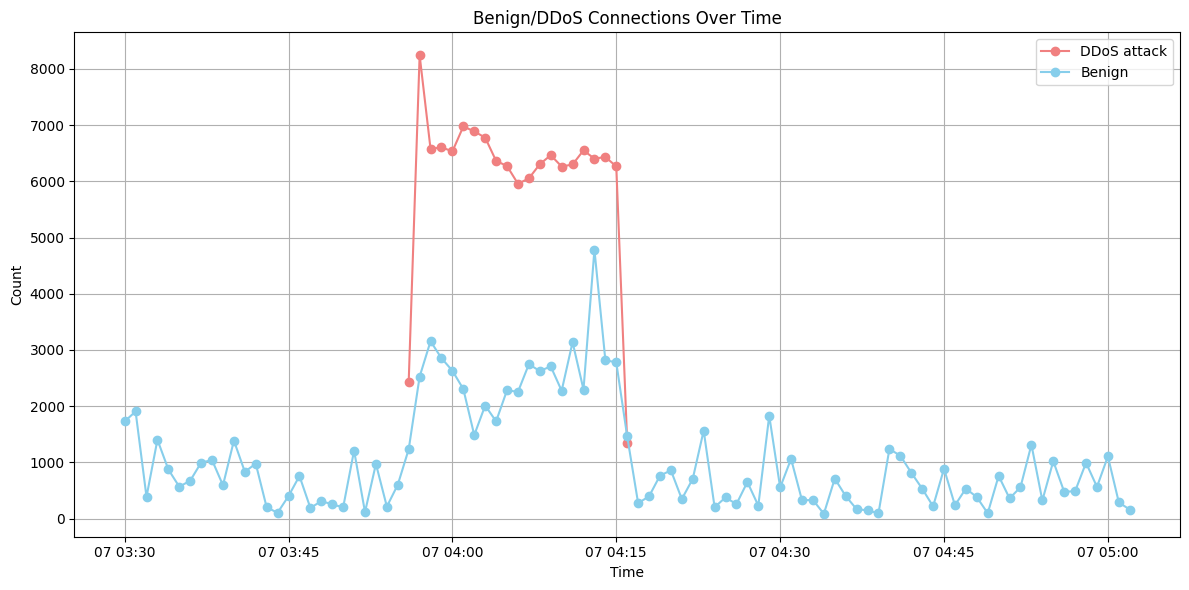

In [37]:
# %%cache connectiontimeplot --show
connection_by_time_b = data[data['Label'] == 'BENIGN'].groupby('Timestamp').size()
connection_by_time_nb = data[data['Label'] != 'BENIGN'].groupby('Timestamp').size()

fig, ax = plt.subplots(figsize=(12, 6))  # This ensures fig stays current
ax.plot(connection_by_time_nb.index, connection_by_time_nb.values, marker='o', linestyle='-', label='DDoS attack', color='lightcoral')
ax.plot(connection_by_time_b.index, connection_by_time_b.values, marker='o', linestyle='-', label='Benign', color='skyblue')
ax.set_title('Benign/DDoS Connections Over Time')
ax.set_xlabel('Time')
ax.set_ylabel('Count')
ax.grid(True)
ax.legend()
plt.tight_layout()

#### Plot the distribution of binary feature data

Plotting Fwd PSH Flags on axis 0
Plotting FIN Flag Count on axis 1
Plotting RST Flag Count on axis 2
Plotting PSH Flag Count on axis 3
Plotting ACK Flag Count on axis 4
Plotting URG Flag Count on axis 5
Plotting Label on axis 6
Completed plotting. Figure has 8 axes


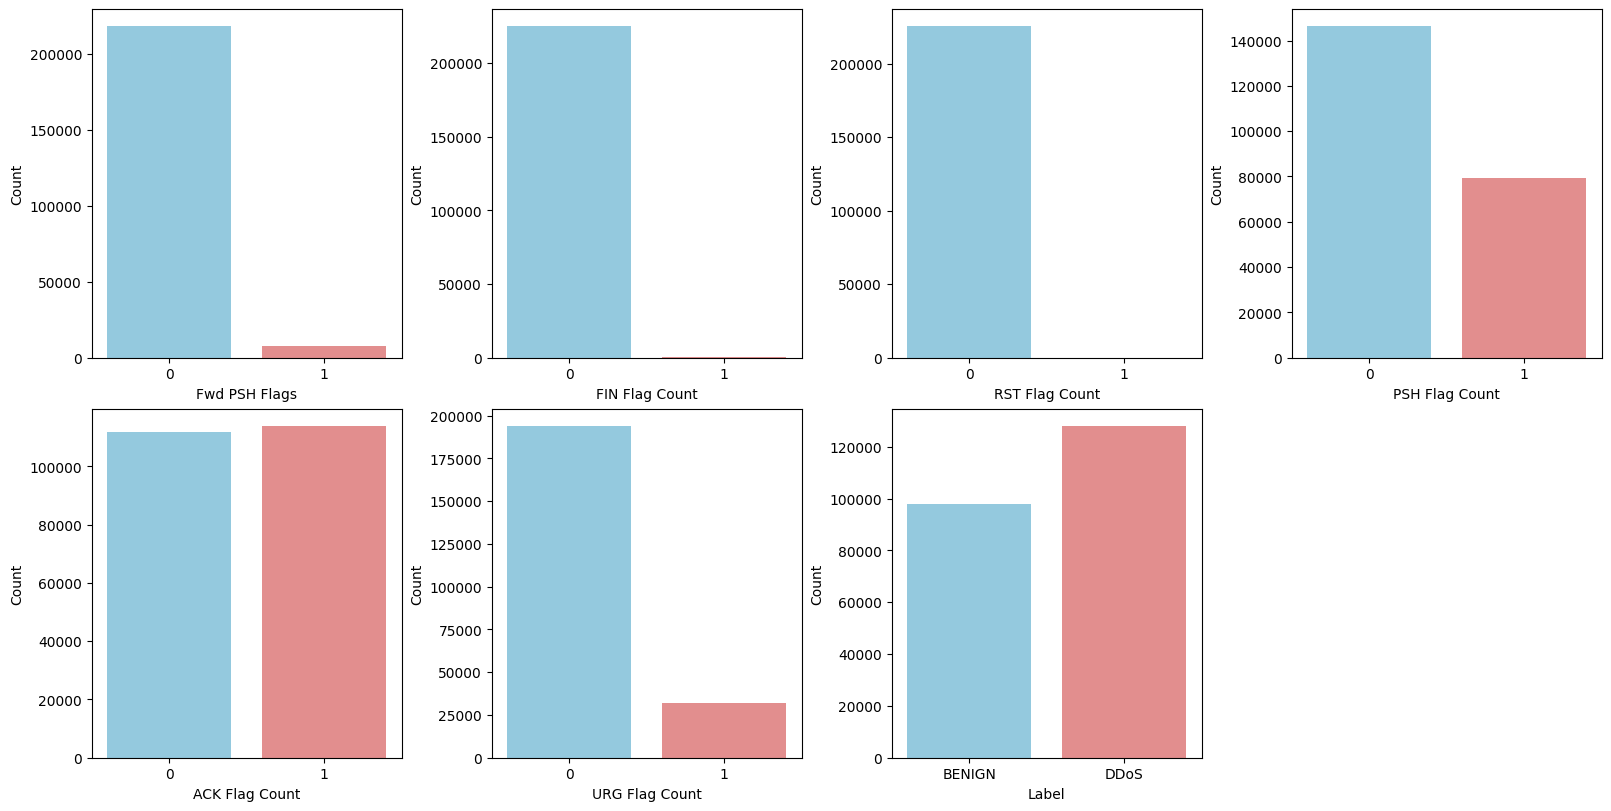

In [38]:
# %%cache binaryfeatureplot --show
fig, ax = plt.subplots(2, 4, figsize=(16, 8), constrained_layout=True)
ax[1,3].set_axis_off()
ax = ax.flatten()

# Add error handling to see what's happening
try:
   for index, column in enumerate(binary_columns):
       print(f"Plotting {column} on axis {index}")
       sns.countplot(data=data, x=column, ax=ax[index], palette=['skyblue','lightcoral'])
       ax[index].set_xlabel(column)
       ax[index].set_ylabel('Count')
   print(f"Completed plotting. Figure has {len(fig.get_axes())} axes")
except Exception as e:
   print(f"Error during plotting: {e}")

# Explicitly prevent figure from being cleared
fig.show = lambda: None  # Override show method to prevent clearing

#### Plot distribution of binary feature by label

Plotting Fwd PSH Flags on axis 0
Plotting FIN Flag Count on axis 1
Plotting RST Flag Count on axis 2
Plotting PSH Flag Count on axis 3
Plotting ACK Flag Count on axis 4
Plotting URG Flag Count on axis 5
Plotting Label on axis 6
Completed plotting. Figure has 8 axes


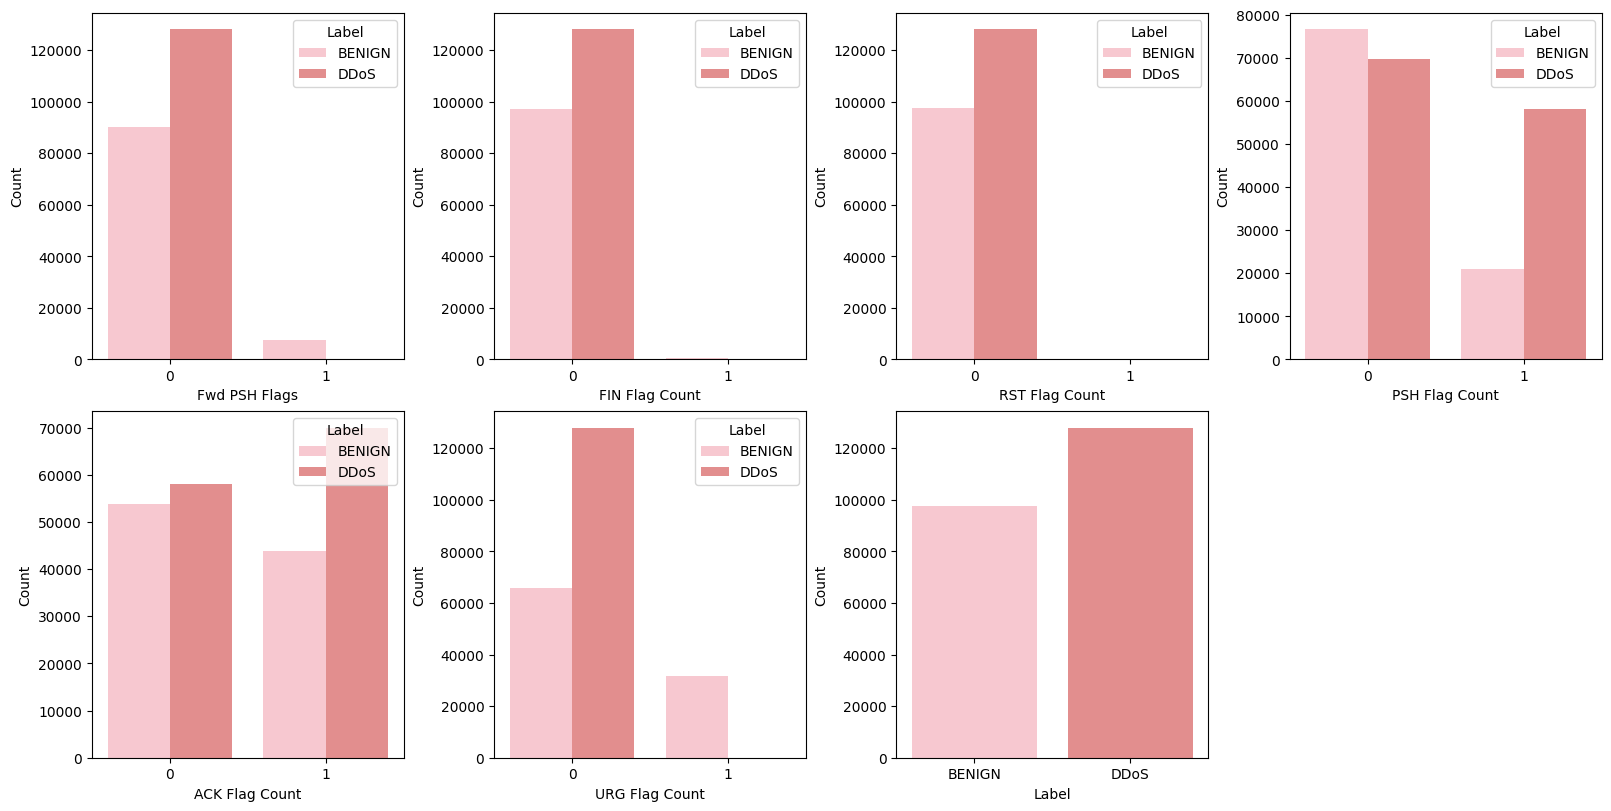

In [39]:
# %%cache binnaryfeaturelabelplot --show
fig, ax = plt.subplots(2, 4, figsize=(16, 8), constrained_layout=True)
ax[1,3].set_axis_off()
ax = ax.flatten()

# Add error handling to see what's happening
try:
    for index, column in enumerate(binary_columns):
        print(f"Plotting {column} on axis {index}")
        sns.countplot(data=data, x=column, hue='Label', ax=ax[index], palette=['pink','lightcoral'])
        ax[index].set_xlabel(column)
        ax[index].set_ylabel('Count')
    print(f"Completed plotting. Figure has {len(fig.get_axes())} axes")
except Exception as e:
    print(f"Error during plotting: {e}")

# Explicitly prevent figure from being cleared
fig.show = lambda: None  # Override show method to prevent clearing

#### categorical features

In [40]:
data[categorical_features]

,Source IP,Destination IP,Label
0,104.16.207.165,192.168.10.5,BENIGN
1,104.16.28.216,192.168.10.5,BENIGN
2,104.16.28.216,192.168.10.5,BENIGN
3,104.17.241.25,192.168.10.16,BENIGN
4,104.19.196.102,192.168.10.5,BENIGN
...,...,...,...
225740,72.21.91.29,192.168.10.15,BENIGN
225741,72.21.91.29,192.168.10.15,BENIGN
225742,72.21.91.29,192.168.10.15,BENIGN
225743,8.41.222.187,192.168.10.15,BENIGN


#### view protocol distribution

(np.float64(-1.0999999866959547),
 np.float64(1.0999998226168308),
 np.float64(-1.0999999285154247),
 np.float64(1.0999999311004418))

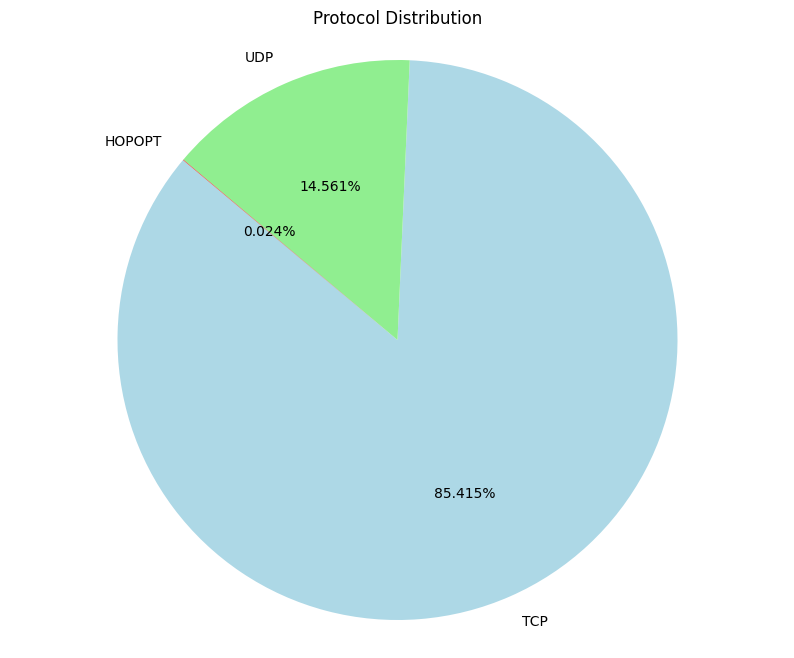

In [41]:
# %%cache protocolpieplot --show
protocol_counts = data['Protocol'].value_counts()

protocol_names = {
    6: 'TCP',
    17: 'UDP',
    0: 'HOPOPT'
}

# Map protocol numbers to names
protocol_counts.index = protocol_counts.index.map(protocol_names)

# Create figure and axis explicitly
fig, ax = plt.subplots(figsize=(10, 8))

# Plot pie chart on the specified axis
ax.pie(protocol_counts,
       labels=protocol_counts.index,
       autopct='%1.3f%%',
       startangle=140,
       colors=['lightblue', 'lightgreen', 'red'])

ax.set_title('Protocol Distribution')
ax.axis('equal')  # Ensures pie is a circle

#### distribution of numeric feature

In [ ]:
# %%cache numericboxplot --show
fig, ax = plt.subplots(figsize=(30, 15))  # Create figure and axis explicitly
sns.boxplot(data=data[numerical_features], ax=ax)

ax.set_title('Boxplot of Numeric Features')
ax.tick_params(axis='x', rotation=45)  # Rotate x-axis labels
fig.tight_layout()

#### Outliers present. scale with standard scaler to reduce impact of outliers

#### Label distribution

In [ ]:
# %%cache labelpieplot --show
print(data['Label'].value_counts())

fig, ax = plt.subplots(figsize=(8, 8))  # Explicit figure and axis
data['Label'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    colors=['lightcoral', 'pink'],
    ax=ax
)

ax.set_title('Label Distribution')
ax.set_ylabel('')  # Remove y-axis label
fig.tight_layout()

#### Protocol distribution by Label

In [ ]:
# %%cache protocollabelplot --show

fig, ax = plt.subplots(figsize=(10, 6))  # Create figure and axis
sns.countplot(data=data, x='Protocol', hue='Label', palette=['pink', 'lightcoral'], ax=ax)

ax.set_xlabel('Protocol')
ax.set_ylabel('Count')
ax.set_title("Protocol Distribution by DDoS Attack")
ax.legend(title='Label')

fig.tight_layout()

## Label encoding for categorical features

In [ ]:
%pip install scikit-learn

In [ ]:
# Function to encode ' Label'
def encode_label(data):
    data['Label'] = data['Label'].map(lambda x: 0 if x == 'BENIGN' else 1)

def handle_ip_port_columns(df):
    """
    Simple replacement for IP/Port columns that generalizes across any dataset.
    Only handles the 4 problematic columns, leaves everything else untouched.

    Args:
        df: DataFrame with 'Source IP', 'Source Port', 'Destination IP', 'Destination Port'

    Returns:
        df: DataFrame with those 4 columns replaced by 8 generalizable features
    """

    df_new = df.copy()

    # === SOURCE IP FEATURES ===
    # Extract network class information (always generalizes)
    df_new['src_is_private'] = df_new['Source IP'].apply(is_private_ip)
    df_new['src_is_multicast'] = df_new['Source IP'].apply(is_multicast_ip)

    # === DESTINATION IP FEATURES ===
    df_new['dst_is_private'] = df_new['Destination IP'].apply(is_private_ip)
    df_new['dst_is_multicast'] = df_new['Destination IP'].apply(is_multicast_ip)

    # === SOURCE PORT FEATURES ===
    # Port range categories (universal across all networks)
    df_new['src_port_category'] = df_new['Source Port'].apply(categorize_port)

    # === DESTINATION PORT FEATURES ===
    df_new['dst_port_category'] = df_new['Destination Port'].apply(categorize_port)
    df_new['dst_is_web_port'] = ((df_new['Destination Port'] == 80) |
                                 (df_new['Destination Port'] == 443)).astype(int)
    df_new['dst_is_common_service'] = df_new['Destination Port'].isin([22, 25, 53, 110, 143]).astype(int)

    # Remove original problematic columns
    df_new = df_new.drop(['Source IP', 'Source Port', 'Destination IP', 'Destination Port'], axis=1)

    return df_new

def is_private_ip(ip_str):
    """Check if IP is in private ranges (RFC 1918)"""
    try:
        octets = [int(x) for x in str(ip_str).split('.')]
        # 10.0.0.0/8, 172.16.0.0/12, 192.168.0.0/16
        return ((octets[0] == 10) or
                (octets[0] == 172 and 16 <= octets[1] <= 31) or
                (octets[0] == 192 and octets[1] == 168))
    except:
        return False

def is_multicast_ip(ip_str):
    """Check if IP is multicast (224.0.0.0/4)"""
    try:
        first_octet = int(str(ip_str).split('.')[0])
        return 224 <= first_octet <= 239
    except:
        return False

def categorize_port(port):
    """
    Categorize ports into standard ranges that are universal across all networks:
    0 = Well-known (0-1023)
    1 = Registered (1024-49151)
    2 = Dynamic/Private (49152-65535)
    """
    if port < 1024:
        return 0  # Well-known ports
    elif port < 49152:
        return 1  # Registered ports
    else:
        return 2  # Dynamic ports


In [ ]:
encode_label(data)
data = handle_ip_port_columns(data)

In [ ]:
# set label as the last column
label_col = 'Label'
label_data = data.pop(label_col)
data[label_col] = label_data

In [ ]:
data

## Check for correlation
- remove highly correlated columns

In [ ]:
#%%cache elimination3
# drop timestamp and measure feature correlation
data.drop('Timestamp',axis=1, inplace =True)

In [ ]:
data.corr()

In [ ]:
correlation_matrix = data.corr()

In [ ]:
# %%cache corrplot --show

fig, ax = plt.subplots(figsize=(15, 15))  # Create figure and axis
sns.heatmap(correlation_matrix.round(2), ax=ax)
ax.set_title('Correlation heatmap of features')

fig.tight_layout()

In [ ]:
# Eliminate correlation group using 0.9 as the threshold

# Get the highly correlated features (absolute correlation > 0.9)
highly_correlated = correlation_matrix.abs() > 0.9

# Extract the indices of highly correlated features
correlated_features = [(feature1, feature2) for feature1 in correlation_matrix.columns
                       for feature2 in correlation_matrix.columns
                       if highly_correlated.loc[feature1, feature2] and feature1 != feature2]

# Print the highly correlated feature pairs
printed_pairs = set()
correlated_groups = {}
for feature1, feature2 in correlated_features:
    if (feature2, feature1) not in printed_pairs:  # Check if the pair has already been printed
        print(f"{feature1} and {feature2} are highly correlated: {correlation_matrix.loc[feature1, feature2]}")
        correlated_groups.setdefault(feature1,[]).append(feature2)
        printed_pairs.add((feature1, feature2))

In [ ]:
# view correlations
correlated_groups

In [ ]:
elimination_by_corr =[]
for group_key in correlated_groups:
    items = correlated_groups.get(group_key) + ['Label']
    items.append(group_key)
    correlation = data[items].corr().abs()

    # Get the correlation of each feature with the 'Label' column
    label_correlation = correlation['Label'].drop('Label').sort_values(ascending=False)
    elimination_by_corr.extend(list(label_correlation.index[1:]))
    print(f"Column '{label_correlation.index[0]}' picked, column {list(label_correlation.index[1:])} to be eliminated")

    print(label_correlation)

In [ ]:
set(elimination_by_corr)

In [ ]:

data.drop(elimination_by_corr, axis =1, inplace = True)

In [ ]:
data

#### we now have 39 features and label for our model training

In [ ]:
data.nunique()

In [ ]:
# drop any contant value
data.drop('src_is_multicast', axis=1, inplace=True)

In [ ]:
data.isnull().sum()

In [ ]:
# Create interactive scrollable display with sticky headers
desc = data.describe().T
display(desc.style.set_table_styles([
    # Sticky left column (row headers/column names)
    {'selector': 'th', 'props': [('position', 'sticky'), ('left', '0'), ('background-color', 'blue'), ('z-index', '2')]},
    # Sticky top row (column headers/statistics)
    {'selector': 'thead th', 'props': [('position', 'sticky'), ('top', '0'), ('background-color', 'gray'), ('z-index', '3')]},
    # Corner cell (top-left) gets highest z-index
    {'selector': 'thead th:first-child', 'props': [('z-index', '4'), ('background-color', 'lightblue')]}
]))

## Save and load dataset

In [ ]:
# Create artifact folder if it doesn't exist
artifact_dir = 'artifacts'
os.makedirs(artifact_dir, exist_ok=True)

# Save dataset
def save_dataset(df, filename='processed_data.csv'):
    file_path = os.path.join(artifact_dir, filename)
    df.to_csv(file_path, index=False)
    print(f"Dataset saved to: {file_path}")


# Usage
save_dataset(data, 'ddos_processed_dataset.csv')

## Working with the prepared data

In [ ]:
# Load dataset from artifact folder
def load_dataset(filename='processed_data.csv'):
    file_path = os.path.join(artifact_dir, filename)
    df = pd.read_csv(file_path)
    print(f"Dataset loaded from: {file_path}")
    print(f"Shape: {df.shape}")
    return df


# Usage
df = load_dataset('ddos_processed_dataset.csv')

In [ ]:
# feature count
feature_count=len(df.columns) - 1
feature_count

## Data preprocessing step

#### scale non_binary features

In [ ]:
exclude_cols = ['Protocol', 'src_port_category', 'dst_port_category']
mask = (df.nunique() > 2) & (~df.columns.isin(exclude_cols))
non_binary_columns = df.columns[mask]
non_binary_columns

In [ ]:
class NetworkDataScaler:
    """
    Improved scaler for network intrusion detection data that handles
    distribution shifts and out-of-range values properly.
    """

    def __init__(self, scaler_type='robust', handle_outliers=True):
        """
        Initialize the scaler.

        Args:
            scaler_type: 'minmax', 'robust', or 'standard'
            handle_outliers: Whether to cap extreme outliers
        """
        self.scaler_type = scaler_type
        self.handle_outliers = handle_outliers
        self.scalers = {}
        self.feature_stats = {}
        self.non_binary_columns = []

        if scaler_type == 'minmax':
            self.base_scaler = MinMaxScaler
        elif scaler_type == 'robust':
            self.base_scaler = RobustScaler  # Less sensitive to outliers
        else:
            self.base_scaler = StandardScaler

    def _identify_binary_columns(self, df, threshold=3):
        """Identify binary/categorical columns."""
        binary_cols = []
        for col in df.columns:
            unique_vals = df[col].nunique()
            if unique_vals <= threshold:
                binary_cols.append(col)
        return binary_cols

    def _detect_outliers(self, series, method='iqr', factor=3):
        """Detect outliers using IQR method."""
        if method == 'iqr':
            Q1 = series.quantile(0.25)
            Q3 = series.quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - factor * IQR
            upper_bound = Q3 + factor * IQR
        else:  # std method
            mean = series.mean()
            std = series.std()
            lower_bound = mean - factor * std
            upper_bound = mean + factor * std

        return lower_bound, upper_bound

    def fit(self, df, label_col='Label'):
        """
        Fit the scaler on training data.

        Args:
            df: Training DataFrame
            label_col: Name of label column
        """
        # Identify binary columns
        binary_cols = self._identify_binary_columns(df)
        self.non_binary_columns = [col for col in df.columns
                                   if col not in binary_cols and col != label_col]

        print(f"Identified {len(binary_cols)} binary columns")
        print(f"Will scale {len(self.non_binary_columns)} continuous columns")

        # Fit scalers and collect statistics
        for col in self.non_binary_columns:
            # Collect detailed statistics
            self.feature_stats[col] = {
                'min': df[col].min(),
                'max': df[col].max(),
                'mean': df[col].mean(),
                'std': df[col].std(),
                'q25': df[col].quantile(0.25),
                'q75': df[col].quantile(0.75),
                'q99': df[col].quantile(0.99)
            }

            # Handle outliers if requested
            if self.handle_outliers:
                lower_bound, upper_bound = self._detect_outliers(df[col])
                self.feature_stats[col]['outlier_lower'] = lower_bound
                self.feature_stats[col]['outlier_upper'] = upper_bound

                # Cap outliers for training
                capped_values = df[col].clip(lower_bound, upper_bound)
            else:
                capped_values = df[col]

            # Fit individual scaler
            scaler = self.base_scaler()
            self.scalers[col] = scaler.fit(capped_values.values.reshape(-1, 1))

        return self

    def transform(self, df, warn_on_outliers=True):
        """
        Transform new data using fitted scalers.

        Args:
            df: DataFrame to transform
            warn_on_outliers: Whether to warn about out-of-range values
        """
        df_transformed = df.copy()
        outlier_warnings = []

        for col in self.non_binary_columns:
            if col not in df.columns:
                raise ValueError(f"Column '{col}' missing from new data")

            # Check for extreme outliers
            if warn_on_outliers and col in self.feature_stats:
                train_min = self.feature_stats[col]['min']
                train_max = self.feature_stats[col]['max']
                new_min = df[col].min()
                new_max = df[col].max()

                if new_min < train_min * 0.1 or new_max > train_max * 10:
                    outlier_warnings.append(f"{col}: train range [{train_min:.2f}, {train_max:.2f}], "
                                            f"new range [{new_min:.2f}, {new_max:.2f}]")

            # Apply outlier capping if used during training
            if self.handle_outliers and col in self.feature_stats:
                lower_bound = self.feature_stats[col]['outlier_lower']
                upper_bound = self.feature_stats[col]['outlier_upper']
                values_to_scale = df[col].clip(lower_bound, upper_bound)
            else:
                values_to_scale = df[col]

            # Transform using fitted scaler
            scaled_values = self.scalers[col].transform(
                values_to_scale.values.reshape(-1, 1))
            df_transformed[col] = scaled_values.flatten()

        # Print warnings if any
        if outlier_warnings:
            warnings.warn(f"Detected significant distribution shifts in {len(outlier_warnings)} features:\n" +
                          "\n".join(outlier_warnings[:5]))  # Show first 5

        return df_transformed

    def save(self, filepath):
        """Save the fitted scaler."""
        scaler_data = {
            'scalers': self.scalers,
            'feature_stats': self.feature_stats,
            'non_binary_columns': self.non_binary_columns,
            'scaler_type': self.scaler_type,
            'handle_outliers': self.handle_outliers
        }
        joblib.dump(scaler_data, filepath)

    @classmethod
    def load(cls, filepath):
        """Load a fitted scaler."""
        scaler_data = joblib.load(filepath)

        # Create instance
        instance = cls(
            scaler_type=scaler_data['scaler_type'],
            handle_outliers=scaler_data['handle_outliers']
        )

        # Restore fitted state
        instance.scalers = scaler_data['scalers']
        instance.feature_stats = scaler_data['feature_stats']
        instance.non_binary_columns = scaler_data['non_binary_columns']

        return instance

# Usage example


def setup_scaler(train_df, scaler_name='scaler'):
    """Set up and save the improved scaler."""

    # Create scaler directory
    os.makedirs('scalers', exist_ok=True)
    scaler_path = os.path.join('scalers', f'{scaler_name}.pkl')

    # Initialize and fit scaler
    scaler = NetworkDataScaler(scaler_type='robust', handle_outliers=True)
    scaler.fit(train_df, label_col='Label')

    # Save scaler
    scaler.save(scaler_path)

    print(f"Scaler fitted and saved to {scaler_path}")
    return scaler


def apply_scaler(test_df, scaler_name='scaler'):
    """Load and apply the improved scaler to new data."""

    scaler_path = os.path.join('scalers', f'{scaler_name}.pkl')

    # Load scaler
    scaler = NetworkDataScaler.load(scaler_path)

    # Transform data
    transformed_df = scaler.transform(test_df, warn_on_outliers=True)

    return transformed_df


def window_split_scaling(df_raw, n_past=10, n_future=1, label_col='Label',
                         train_ratio=0.8, scaler_name='time_series_scaler'):
    """
    Create time series windows with leak-free scaling.

    Process: Raw Data -> Create Windows -> Split Windows -> Scale Training -> Apply to Test

    Args:
        df_raw: Raw unscaled DataFrame
        n_past: Number of past time steps per window
        n_future: Number of future time steps to predict
        label_col: Name of label column
        train_ratio: Proportion of data for training
        scaler_name: Name for saving/loading scaler

    Returns:
        trainX, trainY, testX, testY, scaler_path
    """

    # Extract feature column names
    feature_cols = [col for col in df_raw.columns if col != label_col]

    # Create windows from raw data
    X_raw = []
    y_raw = []

    for i in range(n_past, len(df_raw) - n_future + 1):
        X_raw.append(df_raw.iloc[i-n_past:i][feature_cols].values)
        y_raw.append(df_raw.iloc[i+n_future-1][label_col])

    X_raw = np.array(X_raw)  # Shape: (n_windows, n_timesteps, n_features)
    y_raw = np.array(y_raw)

    # Split windows chronologically
    split_point = int(len(X_raw) * train_ratio)
    trainX_raw = X_raw[:split_point]
    testX_raw = X_raw[split_point:]
    trainY = y_raw[:split_point]
    testY = y_raw[split_point:]

    # Reshape training windows to 2D for scaler fitting
    train_2d = trainX_raw.reshape(-1, trainX_raw.shape[-1])
    train_df = pd.DataFrame(train_2d, columns=feature_cols)

    # Fit scaler only on training data
    scaler = setup_scaler(train_df, scaler_name)

    # Scale training windows
    train_scaled_2d = apply_scaler(train_df, scaler_name)
    trainX_scaled = train_scaled_2d.values.reshape(trainX_raw.shape)

    # Scale test windows using same scaler
    test_2d = testX_raw.reshape(-1, testX_raw.shape[-1])
    test_df = pd.DataFrame(test_2d, columns=feature_cols)
    test_scaled_2d = apply_scaler(test_df, scaler_name)
    testX_scaled = test_scaled_2d.values.reshape(testX_raw.shape)

    scaler_path = os.path.join('scalers', f'{scaler_name}.pkl')

    return trainX_scaled, trainY, testX_scaled, testY, scaler_path


# Diagnostic function

def compare_data_distributions(train_df, test_df, feature_cols=None):
    """Compare statistical distributions between train and test data."""

    if feature_cols is None:
        feature_cols = [col for col in train_df.columns if col != 'Label']

    print("Distribution Comparison (Train vs Test):")
    print("-" * 60)
    print(f"{'Feature':<25} {'Train Mean':<12} {'Test Mean':<12} {'Ratio':<8}")
    print("-" * 60)

    suspicious_features = []

    for col in feature_cols[:10]:  # Show first 10 features
        if col in train_df.columns and col in test_df.columns:
            train_mean = train_df[col].mean()
            test_mean = test_df[col].mean()

            if train_mean != 0:
                ratio = test_mean / train_mean
                print(
                    f"{col:<25} {train_mean:<12.4f} {test_mean:<12.4f} {ratio:<8.2f}")

                if ratio > 5 or ratio < 0.2:  # Significant difference
                    suspicious_features.append(col)

    if suspicious_features:
        print(
            f"\nSuspicious features with large distribution shifts: {suspicious_features}")

    return suspicious_features

In [ ]:
train_columns = df.columns
train_columns

## Split dataset into time series data

In [ ]:
window_size = 10
# Create windows with leak-free scaling (keeps your scaler save/load pattern)
trainX, trainY, testX, testY, scaler_path = window_split_scaling(
    df,
    n_past=window_size,
    train_ratio=0.8,
    scaler_name='network_scaler'
)

In [ ]:
trainX.shape, trainY.shape, testX.shape, testY.shape

## Create tensor dataset

In [ ]:
# random seed function

def set_seed(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

In [ ]:
set_seed(42)

In [ ]:
# Convert boolean columns to integers (True -> 1, False -> 0)
trainX = trainX.astype(float)
testX = testX.astype(float)
trainY = trainY.astype(float)
testY = testY.astype(float)

In [ ]:
# Converting DataFrame to NumPy arrays before creating tensors
x_train_tensor = torch.from_numpy(trainX).to(dtype=torch.float32)
x_test_tensor = torch.from_numpy(testX).to(dtype=torch.float32)
y_train_tensor = torch.from_numpy(trainY).to(dtype=torch.float32).view(-1, 1)
y_test_tensor = torch.from_numpy(testY).to(dtype=torch.float32).view(-1, 1)

In [ ]:
x_train_tensor.shape

In [ ]:
y_train_tensor.shape

In [ ]:
class SimpleDataset(Dataset):
    """
    A simple dataset for tabular data
    """
    def __init__(self, samples, labels):
        self.samples = samples
        self.labels = labels
        self.n_samples = self.samples.shape[0]

    def __len__(self):
        # Return the total number of samples
        return self.n_samples

    def __getitem__(self, index):
        # Return the sample and label at the given index
        return self.samples[index], self.labels[index]

#### Dataset loading

In [ ]:
# Create PyTorch Datasets
train_dataset = SimpleDataset(x_train_tensor, y_train_tensor)

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, num_workers = 8, pin_memory = True, shuffle=True, worker_init_fn=lambda _: np.random.seed(42))

In [ ]:
test_dataset = SimpleDataset(x_test_tensor, y_test_tensor)

val_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [ ]:
print(len(train_dataset))

In [ ]:
train_dataset[3]

# Experiment manager

In [ ]:
%pip install tensorboard

## Metrics and tensorboard logger

In [ ]:
# Enhanced metric tracker class for recording loss, accuracy, and additional classification metrics
class MetricsTracker:
    """Handles tracking of various training metrics including advanced classification metrics"""

    def __init__(self):
        self.reset()

    def reset(self):
        # Basic metrics
        self.loss = 0
        self.num_correct = 0

        # Phase-specific losses
        self.recon_loss = 0
        self.class_loss = 0
        self.pretrain_loss = 0
        self.encoding_loss = 0

        # Validation metrics
        self.val_loss = 0
        self.val_num_correct = 0
        self.val_recon_loss = 0
        self.val_class_loss = 0

        # Predictions for detailed metrics
        self.predictions = []
        self.labels = []
        self.val_predictions = []
        self.val_labels = []

    def track_loss(self, loss: torch.Tensor, loss_type: str = "total",
                   is_validation: bool = False, batch_size: int = 1):
        """Track different types of losses"""
        loss_value = loss.item() * batch_size

        loss_mapping = {
            "total": "val_loss" if is_validation else "loss",
            "reconstruction": "val_recon_loss" if is_validation else "recon_loss",
            "classification": "val_class_loss" if is_validation else "class_loss",
            "pretrain": "pretrain_loss",  # Only for training
            "encoding": "encoding_loss"   # Only for training
        }

        if loss_type in loss_mapping:
            attr_name = loss_mapping[loss_type]
            if is_validation and loss_type in ["pretrain", "encoding"]:
                return  # Skip validation tracking for these
            setattr(self, attr_name, getattr(self, attr_name) + loss_value)

    def track_predictions(self, preds: torch.Tensor, labels: torch.Tensor,
                         is_validation: bool = False):
        """Track predictions and labels"""
        if is_validation:
            self.val_predictions.append(preds.detach().cpu())
            self.val_labels.append(labels.detach().cpu())
        else:
            self.predictions.append(preds.detach().cpu())
            self.labels.append(labels.detach().cpu())

    def calculate_accuracy(self, preds: torch.Tensor, labels: torch.Tensor) -> int:
        """Calculate number of correct predictions"""
        if preds.shape[1] == 1:  # Binary classification
            predicted = torch.sigmoid(preds) > 0.5
            labels = labels.view_as(predicted)
            return predicted.eq(labels).sum().item()
        else:  # Multi-class classification
            return preds.argmax(dim=1).eq(labels).sum().item()

    def get_classification_data(self, is_validation: bool = False):
        """Get classification data for plotting"""
        if is_validation:
            if not self.val_predictions or not self.val_labels:
                return None, None, None

            all_preds = torch.cat(self.val_predictions, dim=0)
            all_labels = torch.cat(self.val_labels, dim=0)
        else:
            if not self.predictions or not self.labels:
                return None, None, None

            all_preds = torch.cat(self.predictions, dim=0)
            all_labels = torch.cat(self.labels, dim=0)

        # Convert to numpy
        labels_np = all_labels.numpy()

        if all_preds.shape[1] == 1:  # Binary classification
            probs_np = torch.sigmoid(all_preds).numpy().flatten()
            preds_np = (probs_np > 0.5).astype(int)
            labels_np = labels_np.flatten()
        else:  # Multi-class classification
            probs_np = torch.softmax(all_preds, dim=1).numpy()
            preds_np = all_preds.argmax(dim=1).numpy()
            # For multi-class, use max probability as "confidence"
            probs_np = probs_np.max(axis=1)

        return labels_np, preds_np, probs_np

    def calculate_advanced_metrics(self, is_validation: bool = False):
        """Calculate advanced classification metrics"""
        labels_np, preds_np, probs_np = self.get_classification_data(is_validation)

        if labels_np is None or preds_np is None:
            return {}

        try:
            # Convert to ensure proper format
            labels_np = labels_np.astype(int)
            preds_np = preds_np.astype(int)

            # Calculate confusion matrix for sensitivity and specificity
            if len(np.unique(labels_np)) == 2:  # Binary classification
                tn, fp, fn, tp = confusion_matrix(labels_np, preds_np, labels=[0, 1]).ravel()

                # Calculate metrics
                metrics = {
                    'cohen_kappa': cohen_kappa_score(labels_np, preds_np),
                    'f1_score': f1_score(labels_np, preds_np, average='binary'),
                    'precision': precision_score(labels_np, preds_np, average='binary', zero_division=0),
                    'recall': recall_score(labels_np, preds_np, average='binary', zero_division=0),
                    'sensitivity': tp / (tp + fn) if (tp + fn) > 0 else 0,  # Same as recall
                    'specificity': tn / (tn + fp) if (tn + fp) > 0 else 0
                }
            else:  # Multi-class classification
                metrics = {
                    'cohen_kappa': cohen_kappa_score(labels_np, preds_np),
                    'f1_score': f1_score(labels_np, preds_np, average='weighted', zero_division=0),
                    'precision': precision_score(labels_np, preds_np, average='weighted', zero_division=0),
                    'recall': recall_score(labels_np, preds_np, average='weighted', zero_division=0),
                    'sensitivity': recall_score(labels_np, preds_np, average='weighted', zero_division=0),  # Same as recall
                    'specificity': self._calculate_multiclass_specificity(labels_np, preds_np)
                }

            return metrics

        except Exception as e:
            print(f"Warning: Could not calculate advanced metrics: {e}")
            return {}

    def _calculate_multiclass_specificity(self, y_true, y_pred):
        """Calculate specificity for multi-class classification"""
        try:
            cm = confusion_matrix(y_true, y_pred)
            specificity_per_class = []

            for i in range(cm.shape[0]):
                tn = np.sum(cm) - np.sum(cm[i, :]) - np.sum(cm[:, i]) + cm[i, i]
                fp = np.sum(cm[:, i]) - cm[i, i]

                if (tn + fp) > 0:
                    specificity_per_class.append(tn / (tn + fp))
                else:
                    specificity_per_class.append(0)

            return np.mean(specificity_per_class)
        except:
            return 0

# tensorboard handler with plotting capability
class TensorBoardLogger:
    """Handles TensorBoard logging"""

    def __init__(self, writer: SummaryWriter):
        self.writer = writer

    def log_scalars(self, metrics: Dict[str, float], phase: str,
                   epoch: int, prefix: str = ""):
        """Log scalar metrics to TensorBoard"""
        for metric_name, value in metrics.items():
            tag = f"{prefix}_{phase}/{metric_name}" if prefix else f"{phase}/{metric_name}"
            self.writer.add_scalar(tag, value, epoch)

    def log_model_parameters(self, model: nn.Module, phase: str, epoch: int):
        """Log model parameters and gradients"""
        for name, param in model.named_parameters():
            if param.requires_grad:
                self.writer.add_histogram(f"{phase}_{name}", param, epoch)
                if param.grad is not None:
                    self.writer.add_histogram(f"{phase}_{name}.grad", param.grad, epoch)

    def log_network_graph(self, model: nn.Module, sample_input: torch.Tensor):
        """Log network architecture graph"""
        try:
            self.writer.add_graph(model, sample_input)
        except Exception as e:
            print(f"Warning: Could not add network graph to TensorBoard: {e}")

    def _plot_confusion_matrix(self, labels, preds, class_names):
        """Create confusion matrix plot"""
        cm = confusion_matrix(labels, preds)
        fig, ax = plt.subplots(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                   xticklabels=class_names, yticklabels=class_names, ax=ax)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
        ax.set_title("Confusion Matrix")

        # Convert to image tensor
        buf = io.BytesIO()
        plt.savefig(buf, format='png', bbox_inches='tight', dpi=100)
        buf.seek(0)

        # Convert to PIL Image and then to tensor
        image = Image.open(buf)
        image_array = np.array(image)

        plt.close(fig)
        buf.close()

        return torch.tensor(image_array).permute(2, 0, 1)  # Convert to CHW format

    def _plot_pr_roc_curve(self, labels, probs):
        """Create PR and ROC curve plots"""
        labels = np.array(labels)
        probs = np.array(probs)

        # PR Curve
        precision, recall, _ = precision_recall_curve(labels, probs)
        fig_pr, ax_pr = plt.subplots(figsize=(8, 6))
        ax_pr.plot(recall, precision, label="PR Curve", linewidth=2)
        ax_pr.set_xlabel("Recall")
        ax_pr.set_ylabel("Precision")
        ax_pr.set_title("Precision-Recall Curve")
        ax_pr.grid(True, alpha=0.3)
        ax_pr.legend()

        buf_pr = io.BytesIO()
        plt.savefig(buf_pr, format='png', bbox_inches='tight', dpi=100)
        buf_pr.seek(0)

        image_pr = Image.open(buf_pr)
        image_pr_array = np.array(image_pr)
        pr_tensor = torch.tensor(image_pr_array).permute(2, 0, 1)

        plt.close(fig_pr)
        buf_pr.close()

        # ROC Curve
        fpr, tpr, _ = roc_curve(labels, probs)
        roc_auc = auc(fpr, tpr)
        fig_roc, ax_roc = plt.subplots(figsize=(8, 6))
        ax_roc.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.3f})", linewidth=2)
        ax_roc.plot([0, 1], [0, 1], 'k--', alpha=0.5, label="Random")
        ax_roc.set_xlabel("False Positive Rate")
        ax_roc.set_ylabel("True Positive Rate")
        ax_roc.set_title("ROC Curve")
        ax_roc.grid(True, alpha=0.3)
        ax_roc.legend()

        buf_roc = io.BytesIO()
        plt.savefig(buf_roc, format='png', bbox_inches='tight', dpi=100)
        buf_roc.seek(0)

        image_roc = Image.open(buf_roc)
        image_roc_array = np.array(image_roc)
        roc_tensor = torch.tensor(image_roc_array).permute(2, 0, 1)

        plt.close(fig_roc)
        buf_roc.close()

        return pr_tensor, roc_tensor

    def log_classification_metrics(self, labels, preds, probs, class_names, phase, epoch):
        """Log classification metrics with plots to TensorBoard"""
        try:
            # Convert to numpy arrays
            labels = np.array(labels)
            preds = np.array(preds)
            probs = np.array(probs)

            # Confusion matrix
            cm_tensor = self._plot_confusion_matrix(labels, preds, class_names)
            self.writer.add_image(f"{phase}/Confusion_Matrix", cm_tensor, epoch)

            # PR and ROC curves (for binary classification only)
            if len(class_names) == 2:
                pr_tensor, roc_tensor = self._plot_pr_roc_curve(labels, probs)
                self.writer.add_image(f"{phase}/PR_Curve", pr_tensor, epoch)
                self.writer.add_image(f"{phase}/ROC_Curve", roc_tensor, epoch)

        except Exception as e:
            print(f"Warning: Could not log classification metrics plots: {e}")


## Trainer classes

In [ ]:
class BasePhaseTrainer(ABC):
    """Abstract base class for phase-specific trainers"""

    @abstractmethod
    def train_epoch(self, model: nn.Module, train_loader: DataLoader,
                   optimizer: torch.optim.Optimizer, device: torch.device,
                   metrics_tracker: MetricsTracker) -> None:
        """Train one epoch for this phase"""
        pass

    def validate_epoch(self, model: nn.Module, val_loader: DataLoader,
                      device: torch.device, metrics_tracker: MetricsTracker) -> None:
        """Validate one epoch for this phase (optional)"""
        pass


class StandardTrainer(BasePhaseTrainer):
    """Standard training phase trainer"""

    def __init__(self, criterion: nn.Module):
        self.criterion = criterion

    def train_epoch(self, model: nn.Module, train_loader: DataLoader,
                   optimizer: torch.optim.Optimizer, device: torch.device,
                   metrics_tracker: MetricsTracker) -> None:
        model.train()

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)

            # Handle different loss types
            if isinstance(self.criterion, nn.BCEWithLogitsLoss):
                labels = labels.float().view(-1, 1)

            loss = self.criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            # Track metrics
            metrics_tracker.track_loss(loss, "total", batch_size=len(inputs))
            num_correct = metrics_tracker.calculate_accuracy(outputs, labels)
            metrics_tracker.num_correct += num_correct
            metrics_tracker.track_predictions(outputs, labels)

    def validate_epoch(self, model: nn.Module, val_loader: DataLoader,
                      device: torch.device, metrics_tracker: MetricsTracker) -> None:
        model.eval()

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)

                if isinstance(self.criterion, nn.BCEWithLogitsLoss):
                    labels = labels.float().view(-1, 1)

                loss = self.criterion(outputs, labels)

                # Track validation metrics
                metrics_tracker.track_loss(loss, "total", is_validation=True,
                                         batch_size=len(inputs))
                num_correct = metrics_tracker.calculate_accuracy(outputs, labels)
                metrics_tracker.val_num_correct += num_correct
                metrics_tracker.track_predictions(outputs, labels, is_validation=True)


class ReconstructionTrainer(BasePhaseTrainer):
    """Reconstruction-based training (e.g., for autoencoders)"""

    def __init__(self, reconstruction_criterion: nn.Module):
        self.reconstruction_criterion = reconstruction_criterion

    def train_epoch(self, model: nn.Module, train_loader: DataLoader,
                   optimizer: torch.optim.Optimizer, device: torch.device,
                   metrics_tracker: MetricsTracker) -> None:
        model.train()

        for inputs, _ in train_loader:
            inputs = inputs.to(device)

            optimizer.zero_grad()

            # Handle different model outputs
            outputs = model(inputs)
            if isinstance(outputs, tuple):
                if len(outputs) == 3:  # (class_logits, encoded, reconstructed)
                    _, _, reconstructed = outputs
                elif len(outputs) == 2:  # (encoded, reconstructed)
                    _, reconstructed = outputs
                else:
                    reconstructed = outputs[0]
            else:
                reconstructed = outputs

            loss = self.reconstruction_criterion(reconstructed, inputs)
            loss.backward()
            optimizer.step()

            metrics_tracker.track_loss(loss, "reconstruction", batch_size=len(inputs))


class JointTrainer(BasePhaseTrainer):
    """Joint training with multiple loss functions"""

    def __init__(self, classification_criterion: nn.Module,
                 reconstruction_criterion: nn.Module,
                 recon_weight: float = 1.0):
        self.classification_criterion = classification_criterion
        self.reconstruction_criterion = reconstruction_criterion
        self.recon_weight = recon_weight

    def train_epoch(self, model: nn.Module, train_loader: DataLoader,
                   optimizer: torch.optim.Optimizer, device: torch.device,
                   metrics_tracker: MetricsTracker) -> None:
        model.train()

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)

            if isinstance(outputs, tuple) and len(outputs) == 3:
                class_logits, encoded, reconstructed = outputs

                # Classification loss
                if isinstance(self.classification_criterion, nn.BCEWithLogitsLoss):
                    labels_class = labels.float().view(-1, 1)
                else:
                    labels_class = labels

                class_loss = self.classification_criterion(class_logits, labels_class)
                recon_loss = self.reconstruction_criterion(reconstructed, inputs)
                total_loss = class_loss + self.recon_weight * recon_loss

                # Track metrics
                metrics_tracker.track_loss(class_loss, "classification", batch_size=len(inputs))
                metrics_tracker.track_loss(recon_loss, "reconstruction", batch_size=len(inputs))
                metrics_tracker.track_loss(total_loss, "total", batch_size=len(inputs))

                num_correct = metrics_tracker.calculate_accuracy(class_logits, labels)
                metrics_tracker.num_correct += num_correct
                metrics_tracker.track_predictions(class_logits, labels)

            else:
                raise ValueError("Model output format not supported for joint training")

            total_loss.backward()
            optimizer.step()

    def validate_epoch(self, model: nn.Module, val_loader: DataLoader,
                      device: torch.device, metrics_tracker: MetricsTracker) -> None:
        model.eval()

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)

                if isinstance(outputs, tuple) and len(outputs) == 3:
                    class_logits, encoded, reconstructed = outputs

                    if isinstance(self.classification_criterion, nn.BCEWithLogitsLoss):
                        labels_class = labels.float().view(-1, 1)
                    else:
                        labels_class = labels

                    class_loss = self.classification_criterion(class_logits, labels_class)
                    recon_loss = self.reconstruction_criterion(reconstructed, inputs)
                    total_loss = class_loss + self.recon_weight * recon_loss

                    # Track validation metrics
                    metrics_tracker.track_loss(class_loss, "classification",
                                             is_validation=True, batch_size=len(inputs))
                    metrics_tracker.track_loss(recon_loss, "reconstruction",
                                             is_validation=True, batch_size=len(inputs))
                    metrics_tracker.track_loss(total_loss, "total",
                                             is_validation=True, batch_size=len(inputs))

                    num_correct = metrics_tracker.calculate_accuracy(class_logits, labels)
                    metrics_tracker.val_num_correct += num_correct
                    metrics_tracker.track_predictions(class_logits, labels, is_validation=True)


class DBNPretrainer(BasePhaseTrainer):
    """Pretrainer for DBN layers"""

    def __init__(self, pretrain_epochs=10, pretrain_lr=0.001):
        self.pretrain_epochs = pretrain_epochs
        self.pretrain_lr = pretrain_lr

    def train_epoch(self, model: nn.Module, train_loader: DataLoader,
                   optimizer: torch.optim.Optimizer, device: torch.device,
                   metrics_tracker: MetricsTracker) -> None:

        if not isinstance(model, DBNNetwork):
            raise ValueError("DBNPretrainer requires DBNNetwork model")

        total_pretrain_loss = 0

        # Pretrain each RBM layer
        for layer_idx in range(len(model.rbm_layers)):
            print(f"Pretraining RBM layer {layer_idx + 1}/{len(model.rbm_layers)}")

            layer_loss = model.pretrain_rbm(
                layer_idx=layer_idx,
                data_loader=train_loader,
                epochs=self.pretrain_epochs,
                lr=self.pretrain_lr,
                device=device
            )

            total_pretrain_loss += layer_loss
            print(f"Layer {layer_idx + 1} pretrain loss: {layer_loss:.6f}")

        # Transfer RBM weights to DBN layers
        model.transfer_rbm_weights()
        print("Transferred RBM weights to DBN layers")

        # Track pretraining loss
        pretrain_loss_tensor = torch.tensor(total_pretrain_loss)
        metrics_tracker.track_loss(pretrain_loss_tensor, "pretrain",
                                 batch_size=len(train_loader.dataset))


class DBNJointTrainer(BasePhaseTrainer):
    """Joint trainer for DBN with reconstruction and classification"""

    def __init__(self, classification_criterion: nn.Module,
                 reconstruction_criterion: nn.Module,
                 reconstruction_weight: float = 0.1):
        self.classification_criterion = classification_criterion
        self.reconstruction_weight = reconstruction_weight
        self.reconstruction_criterion = reconstruction_criterion

    def train_epoch(self, model: nn.Module, train_loader: DataLoader,
                   optimizer: torch.optim.Optimizer, device: torch.device,
                   metrics_tracker: MetricsTracker) -> None:

        model.train()

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()

            # Forward pass
            class_outputs = model(inputs)
            reconstruction = model.get_reconstruction(inputs)

            # Classification loss
            if isinstance(self.classification_criterion, nn.BCEWithLogitsLoss):
                labels_class = labels.float().view(-1, 1)
            else:
                labels_class = labels

            class_loss = self.classification_criterion(class_outputs, labels_class)

            # Reconstruction loss
            recon_loss = self.reconstruction_criterion(reconstruction, inputs)

            # Combined loss
            total_loss = class_loss + self.reconstruction_weight * recon_loss

            total_loss.backward()
            optimizer.step()

            # Track metrics
            metrics_tracker.track_loss(class_loss, "classification", batch_size=len(inputs))
            metrics_tracker.track_loss(recon_loss, "reconstruction", batch_size=len(inputs))
            metrics_tracker.track_loss(total_loss, "total", batch_size=len(inputs))

            num_correct = metrics_tracker.calculate_accuracy(class_outputs, labels)
            metrics_tracker.num_correct += num_correct
            metrics_tracker.track_predictions(class_outputs, labels)

    def validate_epoch(self, model: nn.Module, val_loader: DataLoader,
                      device: torch.device, metrics_tracker: MetricsTracker) -> None:

        model.eval()

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)

                # Forward pass
                class_outputs = model(inputs)
                reconstruction = model.get_reconstruction(inputs)

                # Classification loss
                if isinstance(self.classification_criterion, nn.BCEWithLogitsLoss):
                    labels_class = labels.float().view(-1, 1)
                else:
                    labels_class = labels

                class_loss = self.classification_criterion(class_outputs, labels_class)
                recon_loss = self.reconstruction_criterion(reconstruction, inputs)
                total_loss = class_loss + self.reconstruction_weight * recon_loss

                # Track validation metrics
                metrics_tracker.track_loss(class_loss, "classification",
                                         is_validation=True, batch_size=len(inputs))
                metrics_tracker.track_loss(recon_loss, "reconstruction",
                                         is_validation=True, batch_size=len(inputs))
                metrics_tracker.track_loss(total_loss, "total",
                                         is_validation=True, batch_size=len(inputs))

                num_correct = metrics_tracker.calculate_accuracy(class_outputs, labels)
                metrics_tracker.val_num_correct += num_correct
                metrics_tracker.track_predictions(class_outputs, labels, is_validation=True)


class CustomTrainer(BasePhaseTrainer):
    """Custom trainer that accepts user-defined training functions"""

    def __init__(self, train_fn: Callable, validate_fn: Optional[Callable] = None):
        self.train_fn = train_fn
        self.validate_fn = validate_fn

    def train_epoch(self, model: nn.Module, train_loader: DataLoader,
                   optimizer: torch.optim.Optimizer, device: torch.device,
                   metrics_tracker: MetricsTracker) -> None:
        self.train_fn(model, train_loader, optimizer, device, metrics_tracker)

    def validate_epoch(self, model: nn.Module, val_loader: DataLoader,
                      device: torch.device, metrics_tracker: MetricsTracker) -> None:
        if self.validate_fn:
            self.validate_fn(model, val_loader, device, metrics_tracker)

## Training phases dataclass

In [ ]:
# Core Enums and Data Classes
class TrainingPhase(Enum):
    PRETRAIN = "pretrain"
    ENCODING = "encoding"
    RECONSTRUCTION = "reconstruction"
    FINE_TUNING = "fine_tuning"
    STANDARD = "standard"
    WARMUP = "warmup"

## Run builder

In [ ]:
# RunBuilder class
class RunBuilder:
    @staticmethod
    def get_runs(params):
        Run = namedtuple('Run', params.keys())
        runs = []
        for value in product(*params.values()):
            runs.append(Run(*value))
        return runs


## Run Manager

In [ ]:
# Run manager class
class RunManager:
    """Main training manager with support for multiple phases and enhanced metrics"""

    def __init__(self, train_type: str, save_dir: str = "runs", class_names: List[str] = None):
        self.save_dir = save_dir
        self.current_run = None
        self.current_epoch = 0
        self.run_data = []
        self.start_time = None
        self.epoch_start_time = None
        self.train_type = train_type
        self.class_names = class_names or ["Class 0", "Class 1"]  # Default for binary

        # Components
        self.tb_logger = None
        self.metrics_tracker = MetricsTracker()

        # Training components
        self.model = None
        self.train_loader = None
        self.val_loader = None

        # For tracking run metadata
        self.run_id = None
        self.run_timestamp = None

    def begin_run(self, run_params: Any, model: nn.Module,
                  train_loader: DataLoader, val_loader: Optional[DataLoader] = None):
        """Initialize a new training run"""
        self.start_time = time.time()
        self.run_timestamp = int(self.start_time)
        self.current_run = run_params
        self.model = model
        self.model_name = model.__class__.__name__
        self.train_loader = train_loader
        self.val_loader = val_loader
        self.current_epoch = 0
        self.run_data = []

        # Generate unique run ID
        self.run_id = f"{self.model_name}_{self.run_timestamp}"

        # Setup TensorBoard
        run_name = f"{self.model_name}/{self.train_type}/{self.train_type}_{run_params}_{int(time.time())}"
        writer = SummaryWriter(log_dir=f"{self.save_dir}/{run_name}")
        self.tb_logger = TensorBoardLogger(writer)

        # Log network graph
        try:
            sample_data, _ = next(iter(train_loader))
            self.tb_logger.log_network_graph(model, sample_data)
        except Exception as e:
            print(f"Warning: Could not log network graph: {e}")

    def end_run(self):
        """Finalize the current run and save summary metrics"""
        if self.tb_logger:
            self.tb_logger.writer.close()

        # Save trained model
        self._save_model()

        # Save summary metrics to best.csv
        self._save_best_metrics()

        # Reset state
        self.current_run = None
        self.current_epoch = 0
        self.model = None
        self.train_loader = None
        self.val_loader = None
        self.run_id = None
        self.run_timestamp = None

    def train_phase(self, phase, trainer, optimizer: torch.optim.Optimizer,
                   epochs: int, device: torch.device):
        """Train for multiple epochs in a specific phase"""
        print(f"Starting {phase.value} phase for {epochs} epochs...")

        for epoch in range(epochs):
            self.begin_epoch()

            # Training
            trainer.train_epoch(self.model, self.train_loader, optimizer,
                              device, self.metrics_tracker)

            # Validation
            if self.val_loader is not None:
                trainer.validate_epoch(self.model, self.val_loader,
                                     device, self.metrics_tracker)

            self.end_epoch(phase)

        print(f"{phase.value} phase completed")

    def begin_epoch(self):
        """Start a new epoch"""
        self.epoch_start_time = time.time()
        self.current_epoch += 1
        self.metrics_tracker.reset()

    def end_epoch(self, phase):
        """Finalize the current epoch"""
        epoch_duration = time.time() - self.epoch_start_time
        run_duration = time.time() - self.start_time

        # Calculate metrics
        train_size = len(self.train_loader.dataset)
        val_size = len(self.val_loader.dataset) if self.val_loader else 0

        results = self._calculate_epoch_metrics(train_size, val_size,
                                              epoch_duration, run_duration, phase)

        # Log to TensorBoard
        self._log_to_tensorboard(results, phase)

        # Log classification metrics with plots
        self._log_classification_plots(phase)

        # Store results
        self.run_data.append(results)

        # Display results
        self._display_results(results)

    def _log_classification_plots(self, phase):
        """Log classification plots to TensorBoard. Implemented by end_epochs"""
        if not self.tb_logger:
            return

        # Training plots
        train_labels, train_preds, train_probs = self.metrics_tracker.get_classification_data(is_validation=False)
        if train_labels is not None:
            self.tb_logger.log_classification_metrics(
                train_labels, train_preds, train_probs,
                self.class_names, f"{phase.value}_Train", self.current_epoch
            )

        # Validation plots
        if self.val_loader is not None:
            val_labels, val_preds, val_probs = self.metrics_tracker.get_classification_data(is_validation=True)
            if val_labels is not None:
                self.tb_logger.log_classification_metrics(
                    val_labels, val_preds, val_probs,
                    self.class_names, f"{phase.value}_Validation", self.current_epoch
                )

    def _calculate_epoch_metrics(self, train_size: int, val_size: int,
                                epoch_duration: float, run_duration: float,
                                phase) -> OrderedDict:
        """Calculate all epoch metrics including advanced classification metrics. Implemented by end_epochs"""
        results = OrderedDict()
        results["epoch"] = self.current_epoch
        results["phase"] = phase.value
        results["epoch_duration"] = epoch_duration
        results["run_duration"] = run_duration

        # Training metrics
        results["train_loss"] = self.metrics_tracker.loss / train_size
        results["train_accuracy"] = self.metrics_tracker.num_correct / train_size

        # Advanced training metrics
        train_advanced_metrics = self.metrics_tracker.calculate_advanced_metrics(is_validation=False)
        for metric_name, metric_value in train_advanced_metrics.items():
            results[f"train_{metric_name}"] = metric_value

        # Validation metrics
        if val_size > 0:
            results["val_loss"] = self.metrics_tracker.val_loss / val_size
            results["val_accuracy"] = self.metrics_tracker.val_num_correct / val_size

            # Advanced validation metrics
            val_advanced_metrics = self.metrics_tracker.calculate_advanced_metrics(is_validation=True)
            for metric_name, metric_value in val_advanced_metrics.items():
                results[f"val_{metric_name}"] = metric_value
        else:
            results["val_loss"] = 0
            results["val_accuracy"] = 0
            # Set validation advanced metrics to 0 if no validation data
            for metric_name in ['cohen_kappa', 'f1_score', 'precision', 'recall', 'sensitivity', 'specificity']:
                results[f"val_{metric_name}"] = 0

        # Phase-specific metrics
        if self.metrics_tracker.recon_loss > 0:
            results["recon_loss"] = self.metrics_tracker.recon_loss / train_size
        if self.metrics_tracker.class_loss > 0:
            results["class_loss"] = self.metrics_tracker.class_loss / train_size
        if self.metrics_tracker.pretrain_loss > 0:
            results["pretrain_loss"] = self.metrics_tracker.pretrain_loss / train_size

        # Add run parameters
        if hasattr(self.current_run, '_asdict'):
            results.update(self.current_run._asdict())

        return results

    def _log_to_tensorboard(self, results: OrderedDict, phase):
        """Log metrics to TensorBoard including advanced metrics. Implemented by end_epochs"""
        if not self.tb_logger:
            return

        # Training metrics
        train_metrics = {
            "Loss": results["train_loss"],
            "Accuracy": results["train_accuracy"]
        }

        # Add advanced training metrics
        for metric_name in ['cohen_kappa', 'f1_score', 'precision', 'recall', 'sensitivity', 'specificity']:
            train_key = f"train_{metric_name}"
            if train_key in results:
                display_name = metric_name.replace('_', ' ').title()
                train_metrics[display_name] = results[train_key]

        # Add phase-specific metrics
        for key in ["recon_loss", "class_loss", "pretrain_loss"]:
            if key in results:
                metric_name = key.replace("_", "_").title()
                train_metrics[metric_name] = results[key]

        self.tb_logger.log_scalars(train_metrics, phase.value,
                                  self.current_epoch, "Train")

        # Validation metrics
        if results["val_loss"] > 0:
            val_metrics = {
                "Loss": results["val_loss"],
                "Accuracy": results["val_accuracy"]
            }

            # Add advanced validation metrics
            for metric_name in ['cohen_kappa', 'f1_score', 'precision', 'recall', 'sensitivity', 'specificity']:
                val_key = f"val_{metric_name}"
                if val_key in results:
                    display_name = metric_name.replace('_', ' ').title()
                    val_metrics[display_name] = results[val_key]

            self.tb_logger.log_scalars(val_metrics, phase.value,
                                      self.current_epoch, "Validation")

        # Log model parameters for certain phases
        if phase.value in ["fine_tuning", "standard"]:
            self.tb_logger.log_model_parameters(self.model, phase.value,
                                              self.current_epoch)

    def _display_results(self, results: OrderedDict):
        """Display epoch results including advanced metrics. Implemented by end_epochs"""
        clear_output(wait=True)

        phase = results["phase"].upper()
        epoch = results["epoch"]

        print(f"\n{phase} - Epoch {epoch} Results:")
        print(f"Train Loss: {results['train_loss']:.6f} | "
              f"Train Accuracy: {results['train_accuracy']:.6f}")

        # Display advanced training metrics
        advanced_train_metrics = []
        for metric in ['f1_score', 'precision', 'recall', 'cohen_kappa', 'sensitivity', 'specificity']:
            key = f"train_{metric}"
            if key in results:
                metric_display = metric.replace('_', ' ').title()
                advanced_train_metrics.append(f"{metric_display}: {results[key]:.6f}")

        if advanced_train_metrics:
            print("Train Advanced Metrics:")
            for i in range(0, len(advanced_train_metrics), 3):  # Display 3 per line
                print(" | ".join(advanced_train_metrics[i:i+3]))

        if results['val_loss'] > 0:
            print(f"Val Loss: {results['val_loss']:.6f} | "
                  f"Val Accuracy: {results['val_accuracy']:.6f}")

            # Display advanced validation metrics
            advanced_val_metrics = []
            for metric in ['f1_score', 'precision', 'recall', 'cohen_kappa', 'sensitivity', 'specificity']:
                key = f"val_{metric}"
                if key in results:
                    metric_display = metric.replace('_', ' ').title()
                    advanced_val_metrics.append(f"{metric_display}: {results[key]:.6f}")

            if advanced_val_metrics:
                print("Val Advanced Metrics:")
                for i in range(0, len(advanced_val_metrics), 3):  # Display 3 per line
                    print(" | ".join(advanced_val_metrics[i:i+3]))

        # Display phase-specific metrics
        for key, label in [("recon_loss", "Reconstruction Loss"),
                          ("class_loss", "Classification Loss"),
                          ("pretrain_loss", "Pretrain Loss")]:
            if key in results:
                print(f"{label}: {results[key]:.6f}")

        print(f"Epoch Duration: {results['epoch_duration']:.2f}s")
        print("-" * 80)

        # Display summary table
        if len(self.run_data) > 0:
            df = pd.DataFrame(self.run_data)
            display(df.round(6))

    def save_results(self, filename: str):
        """Save training results to files"""
        dir = f"data/{self.model_name}" if self.model_name else "data/unknown_model"
        os.makedirs(dir, exist_ok=True)

        # Save as CSV
        df = pd.DataFrame(self.run_data)
        df.to_csv(f'{dir}/{filename}.csv', index=False)

        # Save as JSON
        with open(f'{dir}/{filename}.json', 'w', encoding='utf-8') as f:
            json.dump(self.run_data, f, indent=2)

        print(f"Results saved to {dir}/{filename}.[csv|json]")

    def _get_summary_metrics(self):
        """Get a summary of the best metrics across all epochs. Implemented by _save_best_metrics()"""
        if not self.run_data:
            return None

        df = pd.DataFrame(self.run_data)

        summary = {}

        # Find best epoch for each metric
        for metric in ['train_accuracy', 'val_accuracy', 'train_f1_score', 'val_f1_score']:
            if metric in df.columns:
                best_idx = df[metric].idxmax()
                summary[f'best_{metric}'] = {
                    'value': df.loc[best_idx, metric],
                    'epoch': df.loc[best_idx, 'epoch']
                }

        # Find lowest loss
        for metric in ['train_loss', 'val_loss']:
            if metric in df.columns:
                best_idx = df[metric].idxmin()
                summary[f'best_{metric}'] = {
                    'value': df.loc[best_idx, metric],
                    'epoch': df.loc[best_idx, 'epoch']
                }

        return summary

    def _save_best_metrics(self):
        """Save the best metrics from current run to best.csv. Implemented by end_run()"""
        summary = self._get_summary_metrics()
        if not summary:
            print(f"No data to save to best_{self.model_name}.csv")
            return

        # Create data directory
        dir = f"data/{self.model_name}" if self.model_name else "data/unknown_model"
        os.makedirs(dir, exist_ok=True)
        best_csv_path = f"{dir}/best_{self.model_name}.csv"

        # Prepare row data for this run
        row_data = {
            'run_id': self.run_id,
            'model_name': self.model_name,
            'timestamp': self.run_timestamp,
            'total_epochs': self.current_epoch,
            'total_runtime': time.time() - self.start_time if self.start_time else 0
        }

        # Add run parameters if available
        if hasattr(self.current_run, '_asdict'):
            for key, value in self.current_run._asdict().items():
                row_data[f'param_{key}'] = value

        # Add best metrics
        for metric_key, metric_info in summary.items():
            row_data[f'{metric_key}_value'] = metric_info['value']
            row_data[f'{metric_key}_epoch'] = metric_info['epoch']

        # Convert to DataFrame
        new_row_df = pd.DataFrame([row_data])

        # Load existing data or create new
        try:
            if os.path.exists(best_csv_path):
                existing_df = pd.read_csv(best_csv_path)
                # Append new row
                updated_df = pd.concat([existing_df, new_row_df], ignore_index=True)
            else:
                updated_df = new_row_df
        except Exception as e:
            print(f"Error reading existing best_{self.model_name}.csv: {e}")
            updated_df = new_row_df

        # Save updated DataFrame
        try:
            updated_df.to_csv(best_csv_path, index=False)
            print(f"Best metrics saved to {best_csv_path}")
            print(f"Run ID: {self.run_id}")
        except Exception as e:
            print(f"Error saving to best_{self.model_name}.csv: {e}")

    def _save_model(self):
        """Save the trained model to models directory with robust RNN/LSTM handling"""
        if not self.model or not self.run_id:
            return

        # Create models directory
        models_dir = "models"
        os.makedirs(models_dir, exist_ok=True)

        # Save model with run_id as filename
        model_path = f"{models_dir}/{self.run_id}.pt"

        try:
            # Enhanced model config extraction
            model_config = {
                'input_shape': getattr(self.model, 'input_dim', None) or getattr(self.model, 'n_features', None) or getattr(self.model, 'input_size', None),
                'sequence_length': getattr(self.model, 'sequence_length', None),
                'num_classes': getattr(self.model, 'num_classes', None) or getattr(self.model, 'output_dim', None)
            }

            # Add model-specific configs
            if hasattr(self.model, 'hidden_dims'):
                model_config['hidden_dims'] = self.model.hidden_dims
            if hasattr(self.model, 'hidden_dim'):
                model_config['hidden_dim'] = self.model.hidden_dim
            if hasattr(self.model, 'hidden_size'):
                model_config['hidden_size'] = self.model.hidden_size
            if hasattr(self.model, 'd_model'):
                model_config['d_model'] = self.model.d_model
            if hasattr(self.model, 'nhead'):
                model_config['nhead'] = self.model.nhead
            if hasattr(self.model, 'num_layers'):
                model_config['num_layers'] = self.model.num_layers
            if hasattr(self.model, 'encoding_dims'):
                model_config['encoding_dims'] = self.model.encoding_dims
            if hasattr(self.model, 'use_batch_norm'):
                model_config['use_batch_norm'] = self.model.use_batch_norm
            if hasattr(self.model, 'bidirectional'):
                model_config['bidirectional'] = self.model.bidirectional
            if hasattr(self.model, 'dim_feedforward'):
                model_config['dim_feedforward'] = self.model.dim_feedforward
            if hasattr(self.model, 'dropout'):
                model_config['dropout'] = self.model.dropout
            if hasattr(self.model, 'nonlinearity'):
                model_config['nonlinearity'] = self.model.nonlinearity

            # Get clean state dict for RNN/LSTM models to avoid serialization issues
            if self.model.__class__.__name__ in ['RNNClassifier', 'LSTMNetwork']:
                # Put model in eval mode and clear any cached states
                self.model.eval()

                # For LSTM, clear any stored states that might cause serialization issues
                if hasattr(self.model, 'lstm'):
                    # Reset LSTM states by running a dummy forward pass and clearing
                    with torch.no_grad():
                        dummy_input = torch.zeros(1, 10, model_config.get('input_shape', 38))
                        if hasattr(self.model, 'device'):
                            dummy_input = dummy_input.to(self.model.device)
                        _ = self.model(dummy_input)

                # Get state dict and aggressively clean it
                state_dict = self.model.state_dict()

                # Extremely aggressive cleaning for RNN/LSTM tensors
                clean_state_dict = {}
                for key, value in state_dict.items():
                    # Skip any stored hidden states or temporary tensors
                    if not any(skip_key in key.lower() for skip_key in ['hidden', 'cell', '_hidden', '_cell', 'tmp']):
                        try:
                            # Clone and detach tensor, ensuring it's on CPU and contiguous
                            clean_tensor = value.clone().detach().cpu().contiguous()

                            # Verify tensor shape is valid (no None values)
                            if clean_tensor.shape and all(dim is not None and dim >= 0 for dim in clean_tensor.shape):
                                # For RNN/LSTM, ensure tensors are properly formatted
                                if clean_tensor.dtype == torch.float32 or clean_tensor.dtype == torch.float64:
                                    # Convert to float32 to ensure consistency
                                    clean_tensor = clean_tensor.float()

                                clean_state_dict[key] = clean_tensor
                            else:
                                print(f"Skipping tensor {key} with invalid shape: {clean_tensor.shape}")

                        except Exception as tensor_error:
                            print(f"Error cleaning tensor {key}: {tensor_error}")
                            continue

                # Create ultra-clean save dict with explicit serialization-safe format
                save_dict = {
                    'model_state_dict': clean_state_dict,
                    'model_class': str(self.model.__class__.__name__),  # Ensure string
                    'run_id': str(self.run_id),
                    'model_config': {k: v for k, v in model_config.items() if v is not None}  # Remove None values entirely
                }

                # Only add run_params if it exists and is serializable
                if hasattr(self.current_run, '_asdict'):
                    try:
                        params = self.current_run._asdict()
                        # Clean params to ensure serializability
                        clean_params = {}
                        for k, v in params.items():
                            if v is not None and not callable(v):
                                clean_params[k] = v
                        save_dict['run_params'] = clean_params
                    except:
                        pass  # Skip if not serializable

                # Try multiple saving approaches for RNN/LSTM with ultra-clean data
                save_successful = False
                approaches = [
                    # Most conservative approach first
                    lambda: torch.save(save_dict, model_path, pickle_protocol=2, _use_new_zipfile_serialization=False),
                    lambda: torch.save(save_dict, model_path, pickle_protocol=3),
                    lambda: torch.save(save_dict, model_path, pickle_protocol=4),
                    lambda: torch.save(save_dict, model_path, _use_new_zipfile_serialization=False),
                    lambda: torch.save(save_dict, model_path),
                ]

                for i, approach in enumerate(approaches):
                    try:
                        approach()
                        print(f"Model saved to {model_path} (approach {i+1})")
                        save_successful = True
                        break
                    except Exception as approach_error:
                        print(f"Save approach {i+1} failed: {approach_error}")
                        continue

                if not save_successful:
                    print(f"All save approaches failed for {self.model.__class__.__name__}")
                    # Try to save just the state dict as last resort
                    try:
                        ultra_minimal_dict = {'model_state_dict': clean_state_dict, 'model_class': str(self.model.__class__.__name__)}
                        torch.save(ultra_minimal_dict, f"{models_dir}/{self.run_id}_ultra_minimal.pt", pickle_protocol=2)
                        print(f"Ultra minimal version saved")
                    except Exception as ultra_error:
                        print(f"Even ultra minimal saving failed: {ultra_error}")
                    return

            else:
                # Standard saving for other models
                save_dict = {
                    'model_state_dict': self.model.state_dict(),
                    'model_class': self.model.__class__.__name__,
                    'run_id': self.run_id,
                    'run_params': self.current_run._asdict() if hasattr(self.current_run, '_asdict') else None,
                    'model_config': model_config
                }
                torch.save(save_dict, model_path)
                print(f"Model saved to {model_path}")

        except Exception as e:
            print(f"Error saving model: {e}")
            # Try to save a minimal version as fallback
            try:
                minimal_save_dict = {
                    'model_state_dict': {k: v.clone().cpu() for k, v in self.model.state_dict().items()},
                    'model_class': self.model.__class__.__name__,
                    'model_config': model_config
                }
                fallback_path = f"{models_dir}/{self.run_id}_minimal.pt"
                torch.save(minimal_save_dict, fallback_path, pickle_protocol=2)
                print(f"Minimal model saved to {fallback_path}")
            except Exception as fallback_error:
                print(f"Fallback saving also failed: {fallback_error}")

    def _load_best_metrics(self):
        """Load and display the best metrics from all runs. Implemented by compare_runs()"""
        dir = f"data/{self.model_name}" if self.model_name else "data/unknown_model"
        best_csv_path = f"{dir}/best_{self.model_name}.csv"

        if not os.path.exists(best_csv_path):
            print(f"No best_{self.model_name}.csv file found")
            return None

        try:
            df = pd.read_csv(best_csv_path)
            print(f"Loaded {len(df)} runs from best_{self.model_name}.csv")
            return df
        except Exception as e:
            print(f"Error loading best_{self.model_name}.csv: {e}")
            return None

    def compare_runs(self, metric='val_accuracy'):
        """Compare runs by a specific metric"""
        df = self._load_best_metrics()
        if df is None:
            return

        metric_col = f'best_{metric}_value'
        if metric_col not in df.columns:
            print(f"Metric {metric} not found in best_{self.model_name}.csv")
            return

        # Sort by metric (descending for accuracy/f1, ascending for loss)
        ascending = 'loss' in metric.lower()
        sorted_df = df.sort_values(metric_col, ascending=ascending)

        print(f"\nRuns ranked by {metric}:")
        display_cols = ['run_id', 'model_name', metric_col, f'best_{metric}_epoch']
        if len(display_cols) <= 4:
            display_cols.extend(['total_epochs', 'total_runtime'])

        # Filter columns that exist
        available_cols = [col for col in display_cols if col in sorted_df.columns]
        print(sorted_df[available_cols].head(10).to_string(index=False))

## Training pipeline

In [ ]:
class TrainingPipeline:
    """High-level training pipeline"""

    @staticmethod
    def train_with_pretraining(model: nn.Module, train_loader: DataLoader,
                              val_loader: DataLoader, run_params: List[Any],
                              pretrain_config: Dict[str, Any],
                              finetune_config: Dict[str, Any],
                              device: torch.device,
                              class_names: List[str] = None) -> RunManager:
        """
        Train model with pretraining phase followed by fine-tuning

        Args:
            pretrain_config: {
                'trainer': BasePhaseTrainer,
                'optimizer': torch.optim.Optimizer,
                'epochs': int,
                'phase': TrainingPhase
            }
            finetune_config: Similar to pretrain_config
        """
        run_manager = RunManager(train_type="train_with_pretrain", class_names=class_names)

        for run in run_params:
            run_manager.begin_run(run, model, train_loader, val_loader)

            # Pretraining phase
            run_manager.train_phase(
                phase=pretrain_config['phase'],
                trainer=pretrain_config['trainer'],
                optimizer=pretrain_config['optimizer'],
                epochs=pretrain_config['epochs'],
                device=device
            )

            # Fine-tuning phase
            run_manager.train_phase(
                phase=finetune_config['phase'],
                trainer=finetune_config['trainer'],
                optimizer=finetune_config['optimizer'],
                epochs=finetune_config['epochs'],
                device=device
            )

            run_manager.end_run()

        return run_manager


    @staticmethod
    def train_standard(model: nn.Module, train_loader: DataLoader,
                        val_loader: DataLoader, run_params: List[Any],
                        trainer: BasePhaseTrainer, optimizer: torch.optim.Optimizer,
                        epochs: int, device: torch.device = None,
                        class_names: List[str] = None) -> RunManager:
        """Standard DBN training (classification only)"""

        if device is None:
            device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

        model = model.to(device)

        # Initialize run manager
        run_manager = RunManager(train_type="standard_train", class_names=class_names, )
        for run in run_params:
            run_manager.begin_run(run, model, train_loader, val_loader)

            run_manager.train_phase(
                phase=TrainingPhase.STANDARD,
                trainer=trainer,
                optimizer=optimizer,
                epochs=epochs,
                device=device
            )

            run_manager.end_run()

        return run_manager

    @staticmethod
    def train_dbn_pretrain_and_finetune(model: nn.Module, train_loader: DataLoader,
                                        val_loader: DataLoader, run_params: List[Any],
                                        pretrain_epochs: int = 5, finetune_epochs: int = 10,
                                        pretrain_lr: float = 0.001, finetune_lr: float = 0.0001,
                                        device: torch.device = None,
                                        class_names: list = None,
                                        reconstruction_weight: float = 0.1):
        """Complete DBN training with pretraining and fine-tuning"""

        if device is None:
            device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

        model = model.to(device)

        # Initialize run manager
        run_manager = RunManager(train_type="pretrain_finetune", class_names=class_names, )
        for run in run_params:
            run_manager.begin_run(run, model, train_loader, val_loader)

            # Phase 1: Pretraining
            print("=" * 60)
            print("PHASE 1: DBN PRETRAINING")
            print("=" * 60)

            pretrain_trainer = DBNPretrainer(
                pretrain_epochs=pretrain_epochs,
                pretrain_lr=pretrain_lr
            )

            # Create optimizer for pretraining (not used in RBM training but required by interface)
            pretrain_optimizer = torch.optim.Adam(model.parameters(), lr=pretrain_lr)

            run_manager.train_phase(
                phase=TrainingPhase.PRETRAIN,
                trainer=pretrain_trainer,
                optimizer=pretrain_optimizer,
                epochs=1,  # Pretraining handled internally
                device=device
            )

            # Phase 2: Fine-tuning with joint training
            print("=" * 60)
            print("PHASE 2: FINE-TUNING WITH JOINT TRAINING")
            print("=" * 60)

            # Classification criterion
            classification_criterion = nn.BCEWithLogitsLoss()
            reconstruction_criterion = nn.MSELoss()

            joint_trainer = DBNJointTrainer(
                classification_criterion=classification_criterion,
                reconstruction_criterion = reconstruction_criterion,
                reconstruction_weight = reconstruction_weight
            )

            # Create optimizer for fine-tuning
            finetune_optimizer = torch.optim.Adam(model.parameters(), lr=finetune_lr)

            run_manager.train_phase(
                phase=TrainingPhase.FINE_TUNING,
                trainer=joint_trainer,
                optimizer=finetune_optimizer,
                epochs=finetune_epochs,
                device=device
            )

            run_manager.end_run()

        return run_manager


## Trainer creator

In [ ]:
# Factory functions for common trainers
class TrainerFactory:
    """Factory for creating common trainer configurations"""

    @staticmethod
    def create_standard_trainer(criterion: nn.Module) -> StandardTrainer:
        return StandardTrainer(criterion)

    @staticmethod
    def create_reconstruction_trainer(reconstruction_criterion: nn.Module) -> ReconstructionTrainer:
        return ReconstructionTrainer(reconstruction_criterion)

    @staticmethod
    def create_joint_trainer(classification_criterion: nn.Module,
                           reconstruction_criterion: nn.Module,
                           recon_weight: float = 1.0) -> JointTrainer:
        return JointTrainer(classification_criterion, reconstruction_criterion, recon_weight)

    @staticmethod
    def create_custom_trainer(train_fn: Callable,
                            validate_fn: Optional[Callable] = None) -> CustomTrainer:
        return CustomTrainer(train_fn, validate_fn)

In [ ]:
# Example 2: Autoencoder with Pretraining and Fine-tuning
def example_autoencoder_training():
    """Example of autoencoder training with pretraining phase"""

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Run parameters
    params = {'lr': [0.001], 'batch_size': [32]}
    runs = RunBuilder.get_runs(params)

    # Loss functions
    reconstruction_criterion = nn.MSELoss()
    classification_criterion = nn.BCEWithLogitsLoss()

    for run in runs:
        # Create trainers
        pretrain_trainer = TrainerFactory.create_reconstruction_trainer(reconstruction_criterion)
        finetune_trainer = TrainerFactory.create_joint_trainer(
            classification_criterion, reconstruction_criterion, recon_weight=0.5
        )

        # Create optimizers (different learning rates for different phases)
        pretrain_optimizer = torch.optim.Adam(model.parameters(), lr=run.lr)
        finetune_optimizer = torch.optim.Adam(model.parameters(), lr=run.lr * 0.1)

        # Training configuration
        pretrain_config = {
            'trainer': pretrain_trainer,
            'optimizer': pretrain_optimizer,
            'epochs': 50,
            'phase': TrainingPhase.PRETRAIN
        }

        finetune_config = {
            'trainer': finetune_trainer,
            'optimizer': finetune_optimizer,
            'epochs': 100,
            'phase': TrainingPhase.FINE_TUNING
        }

        # Train with pretraining
        run_manager = TrainingPipeline.train_with_pretraining(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            run_params=[run],
            pretrain_config=pretrain_config,
            finetune_config=finetune_config,
            device=device
        )

        run_manager.save_results(f"autoencoder_pretrained_{run}")


# Example 3: Custom Multi-Phase Training
def example_custom_multiphase_training():
    """Example of custom multi-phase training"""

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Custom training function for warmup phase
    def warmup_train_fn(model, train_loader, optimizer, device, metrics_tracker):
        model.train()
        for batch_idx, (inputs, labels) in enumerate(train_loader):
            inputs, labels = inputs.to(device), labels.to(device)

            # Gradual learning rate increase during warmup
            lr_scale = min(1.0, (batch_idx + 1) / len(train_loader))
            for param_group in optimizer.param_groups:
                param_group['lr'] = param_group['lr'] * lr_scale

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = nn.Cross

## LSTM model training

In [ ]:
class LSTMNetwork(nn.Module):
    """LSTM Network for sequence classification with GPU support and flexibility."""

    def __init__(
        self,
        input_dim: int,
        hidden_dim: int,
        output_dim: int,
        num_layers: int = 2,
        dropout: float = 0.2,
        bidirectional: bool = False,
        device: torch.device = None
    ):
        super(LSTMNetwork, self).__init__()
        self.device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.bidirectional = bidirectional
        self.direction_factor = 2 if bidirectional else 1

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            dropout=dropout if num_layers > 1 else 0.0,
            batch_first=True,
            bidirectional=bidirectional
        )

        self.fc = nn.Linear(hidden_dim * self.direction_factor, output_dim)
        self.to(self.device)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Forward pass through the LSTM network.

        Args:
            x (torch.Tensor): Input tensor of shape (batch_size, seq_len, input_dim)
                              or (batch_size, input_dim)

        Returns:
            torch.Tensor: Output tensor of shape (batch_size, output_dim)
        """
        x = x.to(self.device)

        # If input is (batch_size, input_dim), reshape it to (batch_size, seq_len=1, input_dim)
        if x.dim() == 2:
            x = x.unsqueeze(1)

        # Initialize hidden and cell states
        h0 = torch.zeros(self.num_layers * self.direction_factor, x.size(0), self.hidden_dim).to(self.device)
        c0 = torch.zeros(self.num_layers * self.direction_factor, x.size(0), self.hidden_dim).to(self.device)

        lstm_out, _ = self.lstm(x, (h0, c0))  # (batch_size, seq_len, hidden_dim * directions)
        last_output = lstm_out[:, -1, :]     # Take output from the last time step

        logits = self.fc(last_output)
        # return torch.sigmoid(logits) # For binary classification
        return logits

In [ ]:
# Example 1: Standard Classification Training
def LSTMNetwork_training():
    """standard model training"""

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Create run parameters
    """
    params = {
        'lr': [0.001, 0.0001],
        'batch_size': [32, 64],
        'dropout': [0.2, 0.3]
    }
    """
    params = OrderedDict(
        lr= [0.001],
        batch_size= [64],
        dropout = [0.2],
        hidden_dim = [32],
        num_layers = [2]
    )
    # Create trainer and optimizer
    criterion = nn.BCEWithLogitsLoss()
    trainer = TrainerFactory.create_standard_trainer(criterion)

    # Train model
    for run in RunBuilder.get_runs(params):
        # Model default initialization with the right dimensions
        input_dim = feature_count  # Number of features
        hidden_dim = 64  # Can be adjusted based on complexity needed
        output_dim = 1   # For binary classification (adjust if needed)
        num_layers = 2   # Using 2 layers as in your model definition

        lstm_model = LSTMNetwork(
            input_dim=input_dim,
            hidden_dim=run.hidden_dim,
            output_dim=output_dim,
            num_layers=run.num_layers,
            dropout=run.dropout,
            bidirectional=False  # Set to True if you want bidirectional LSTM
        )
        # Create PyTorch Datasets
        train_dataset = SimpleDataset(x_train_tensor, y_train_tensor)
        test_dataset = SimpleDataset(x_test_tensor, y_test_tensor)

        # Create DataLoaders
        train_loader = DataLoader(train_dataset, batch_size=run.batch_size, num_workers = 16, pin_memory = True, shuffle=True, worker_init_fn=lambda _: np.random.seed(42))
        val_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
        optimizer = torch.optim.Adam(lstm_model.parameters(), lr=run.lr)

        run_manager = TrainingPipeline.train_standard(
            model=lstm_model,
            train_loader=train_loader,
            val_loader=val_loader,
            run_params=[run],
            trainer=trainer,
            optimizer=optimizer,
            epochs=10,
            device=device,
            class_names=['BENIGN', 'DDOS']
        )

        run_manager.save_results(f"{lstm_model.__class__.__name__}_standard_training_{run}")
    # Compare runs by validation accuracy
    run_manager.compare_runs('val_accuracy')


In [ ]:
%%skip
LSTMNetwork_training()

## DBN model training

In [ ]:
class RBM(nn.Module):
    """Restricted Boltzmann Machine for DBN pretraining"""

    def __init__(self, n_visible, n_hidden, k=1, device=None):
        super(RBM, self).__init__()
        self.device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.to(self.device)
        self.n_visible = n_visible
        self.n_hidden = n_hidden
        self.k = k  # Number of Gibbs sampling steps

        # Initialize weights and biases
        self.W = nn.Parameter(torch.randn(n_visible, n_hidden) * 0.01)
        self.v_bias = nn.Parameter(torch.zeros(n_visible))
        self.h_bias = nn.Parameter(torch.zeros(n_hidden))


    def sample_hidden(self, v):
        """Sample hidden units given visible units"""
        h_prob = torch.sigmoid(F.linear(v, self.W.t(), self.h_bias))
        h_sample = torch.bernoulli(h_prob)
        return h_prob, h_sample

    def sample_visible(self, h):
        """Sample visible units given hidden units"""
        v_prob = torch.sigmoid(F.linear(h, self.W, self.v_bias))
        v_sample = torch.bernoulli(v_prob)
        return v_prob, v_sample

    def forward(self, v):
        """Forward pass - compute hidden probabilities"""
        h_prob, _ = self.sample_hidden(v)
        return h_prob

    def contrastive_divergence(self, v):
        """Contrastive Divergence training"""
        # Positive phase
        h_prob_pos, h_sample = self.sample_hidden(v)

        # Negative phase
        v_neg = v
        for _ in range(self.k):
            h_prob_neg, h_sample_neg = self.sample_hidden(v_neg)
            v_prob_neg, v_neg = self.sample_visible(h_sample_neg)

        h_prob_neg, _ = self.sample_hidden(v_neg)

        # Compute gradients
        positive_grad = torch.matmul(v.t(), h_prob_pos)
        negative_grad = torch.matmul(v_neg.t(), h_prob_neg)

        # Reconstruction error
        reconstruction_loss = F.mse_loss(v, v_prob_neg)

        return reconstruction_loss, positive_grad, negative_grad, h_prob_pos


class DBNNetwork(nn.Module):
    """Deep Belief Network for time series classification"""

    def __init__(self, input_dim, hidden_dims, output_dim, dropout=0.2,
                 sequence_length=10, use_batch_norm=False, device=None):
        super(DBNNetwork, self).__init__()
        self.device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.to(self.device)
        self.input_dim = input_dim
        self.hidden_dims = hidden_dims
        self.output_dim = output_dim
        self.dropout = dropout
        self.sequence_length = sequence_length
        self.use_batch_norm = use_batch_norm

        # Flatten input for DBN processing
        self.flattened_input_dim = input_dim * sequence_length

        # Create RBM layers for pretraining
        self.rbm_layers = nn.ModuleList()
        layer_dims = [self.flattened_input_dim] + hidden_dims

        for i in range(len(layer_dims) - 1):
            rbm = RBM(layer_dims[i], layer_dims[i + 1])
            self.rbm_layers.append(rbm)

        # Create the full DBN network
        self.dbn_layers = nn.ModuleList()
        for i in range(len(layer_dims) - 1):
            layer = nn.Linear(layer_dims[i], layer_dims[i + 1])
            self.dbn_layers.append(layer)

        # Batch normalization layers
        if self.use_batch_norm:
            self.batch_norms = nn.ModuleList([
                nn.BatchNorm1d(dim) for dim in hidden_dims
            ])

        # Dropout layers
        self.dropout_layers = nn.ModuleList([
            nn.Dropout(dropout) for _ in hidden_dims
        ])

        # Classification head
        self.classifier = nn.Linear(hidden_dims[-1], output_dim)

        # Initialize weights
        self._initialize_weights()

    def _initialize_weights(self):
        """Initialize network weights"""
        for layer in self.dbn_layers:
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)

        nn.init.xavier_uniform_(self.classifier.weight)
        nn.init.zeros_(self.classifier.bias)

    def pretrain_rbm(self, layer_idx, data_loader, epochs=10, lr=0.001, device=None):
        """Pretrain a single RBM layer"""
        rbm = self.rbm_layers[layer_idx]
        device = device or self.device
        rbm.to(device)

        optimizer = torch.optim.Adam(rbm.parameters(), lr=lr)

        total_loss = 0
        num_batches = 0

        for epoch in range(epochs):
            epoch_loss = 0
            for batch_data, _ in data_loader:
                batch_data = batch_data.to(device)

                # Flatten the input for RBM processing
                batch_data = batch_data.view(batch_data.size(0), -1)

                # If not the first layer, encode with previous layers
                if layer_idx > 0:
                    with torch.no_grad():
                        for i in range(layer_idx):
                            batch_data = torch.sigmoid(
                                F.linear(batch_data, self.dbn_layers[i].weight,  #removed transpose here
                                        self.dbn_layers[i].bias)
                            )

                optimizer.zero_grad()

                # Perform contrastive divergence
                loss, pos_grad, neg_grad, h_prob = rbm.contrastive_divergence(batch_data)

                # Manual gradient update for CD
                rbm.W.grad = -(pos_grad - neg_grad) / batch_data.size(0)
                rbm.v_bias.grad = -(batch_data.mean(0) -
                                   torch.sigmoid(F.linear(h_prob, rbm.W, rbm.v_bias)).mean(0))
                rbm.h_bias.grad = -(h_prob.mean(0) -
                                   torch.sigmoid(F.linear(batch_data, rbm.W.t(), rbm.h_bias)).mean(0))

                optimizer.step()

                epoch_loss += loss.item()
                num_batches += 1

            total_loss += epoch_loss

        return total_loss / num_batches

    def transfer_rbm_weights(self):
        """Transfer pretrained RBM weights to DBN layers"""
        for i, rbm in enumerate(self.rbm_layers):
            self.dbn_layers[i].weight.data = rbm.W.t().clone()
            self.dbn_layers[i].bias.data = rbm.h_bias.clone()

    def encode(self, x):
        """Encode input through all DBN layers"""
        x = x.to(self.device)
        # Flatten input for processing
        x = x.view(x.size(0), -1)

        for i, layer in enumerate(self.dbn_layers):
            x = F.linear(x, layer.weight, layer.bias) #removed transpose here
            x = torch.sigmoid(x)

            if self.use_batch_norm:
                x = self.batch_norms[i](x)

            x = self.dropout_layers[i](x)

        return x

    def forward(self, x):
        """Forward pass for classification"""
        x = x.to(self.device)
        # Encode through DBN layers
        encoded = self.encode(x)

        # Classification
        output = self.classifier(encoded)

        return output

    def get_reconstruction(self, x):
        """Get reconstruction for visualization/analysis"""
        x = x.to(self.device)
        encoded = self.encode(x)

        # Decode back through layers
        decoded = encoded
        for layer in reversed(self.dbn_layers):
            decoded = F.linear(decoded, layer.weight.t())
            decoded = torch.sigmoid(decoded)

        # Reshape back to original dimensions
        decoded = decoded.view(x.size(0), self.sequence_length, self.input_dim)

        return decoded


In [ ]:
def DBNNetwork_standard_training():
    """Standard DBN training without pretraining"""
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Create run parameters
    params = OrderedDict(
        lr=[0.0001],
        batch_size=[128],
        dropout=[0.2],
        hidden_dims=[[64, 32]],
        use_batch_norm=[True]
    )

    input_dim = feature_count  # Number of features per timestep
    sequence_length = 10  # Length of time sequence
    output_dim = 1   # For binary classification

    # Create trainer
    criterion = nn.BCEWithLogitsLoss()
    trainer = TrainerFactory.create_standard_trainer(criterion)

    for run in RunBuilder.get_runs(params):
        print(f"\nStarting run: {run}")

        # Create DBN model
        dbn_model = DBNNetwork(
            input_dim=input_dim,
            hidden_dims=list(run.hidden_dims),
            output_dim=output_dim,
            dropout=run.dropout,
            sequence_length=sequence_length,
            use_batch_norm=run.use_batch_norm
        )
        dbn_model.to(device)

        # Create DataLoaders
        train_dataset = SimpleDataset(x_train_tensor, y_train_tensor)
        test_dataset = SimpleDataset(x_test_tensor, y_test_tensor)

        train_loader = DataLoader(
            train_dataset,
            batch_size=run.batch_size,
            num_workers=16,
            pin_memory=True,
            shuffle=True,
            worker_init_fn=lambda _: np.random.seed(42)
        )
        val_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

        optimizer = torch.optim.Adam(dbn_model.parameters(), lr=run.lr)

        # Train with standard pipeline
        run_manager = TrainingPipeline.train_standard(
            model=dbn_model,
            train_loader=train_loader,
            val_loader=val_loader,
            run_params=[run],
            trainer=trainer,
            optimizer=optimizer,
            epochs=10,
            device=device,
            class_names=['BENIGN', 'DDOS']
        )

        run_manager.save_results(f"{dbn_model.__class__.__name__}_standard_training_{run}")

    # Compare runs by validation accuracy
    if 'run_manager' in locals():
        run_manager.compare_runs('val_accuracy')


In [ ]:
%%skip
# For quick supervised training
DBNNetwork_standard_training()

## RNN model training

In [ ]:
class RNNClassifier(nn.Module):
    def __init__(self, input_size=feature_count, hidden_size=128, num_layers=2, dropout=0.3, nonlinearity='tanh'):
        super(RNNClassifier, self).__init__()
        self.rnn = nn.RNN(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout,
            nonlinearity=   nonlinearity #'tanh' or 'relu'
        )
        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        _, hn = self.rnn(x)       # hn shape: (num_layers, batch_size, hidden_size)
        last_hidden = hn[-1]
        out = self.fc(last_hidden)
        return out

In [ ]:
def RNNNetwork_training():
    """standard model training"""
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Create run parameters
    params = OrderedDict(
        lr= [0.0001],
        batch_size=[128],
        dropout = [0.2],
        hidden_dim = [128],
        num_layers = [1],
        nonlinearity = ['relu']
    )

    # Create trainer and optimizer
    criterion = nn.BCEWithLogitsLoss()
    trainer = TrainerFactory.create_standard_trainer(criterion)

    # Train model
    for run in tqdm(RunBuilder.get_runs(params)):
        RNN_model = RNNClassifier(
            input_size=feature_count,
            hidden_size=run.hidden_dim,
            num_layers=run.num_layers,
            dropout=run.dropout,
            nonlinearity=run.nonlinearity,
        )
        RNN_model.to(device)
        # Create PyTorch Datasets
        train_dataset = SimpleDataset(x_train_tensor, y_train_tensor)
        test_dataset = SimpleDataset(x_test_tensor, y_test_tensor)
        # Create DataLoaders
        train_loader = DataLoader(train_dataset, batch_size=run.batch_size, num_workers = 16, pin_memory = True, shuffle=True, worker_init_fn=lambda _: np.random.seed(42))
        val_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
        optimizer = torch.optim.Adam(RNN_model.parameters(), lr=run.lr)

        run_manager = TrainingPipeline.train_standard(
            model=RNN_model,
            train_loader=train_loader,
            val_loader=val_loader,
            run_params=[run],
            trainer=trainer,
            optimizer=optimizer,
            epochs=10,
            device=device,
            class_names=['BENIGN', 'DDOS']
        )

        run_manager.save_results(f"{RNN_model.__class__.__name__}_standardtraining{run}")
    # Compare runs by validation accuracy
    run_manager.compare_runs('val_accuracy')

In [ ]:
%%skip
RNNNetwork_training()

## Transformers

In [ ]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super(PositionalEncoding, self).__init__()

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0).transpose(0, 1)

        self.register_buffer('pe', pe)

    def forward(self, x):
        return x + self.pe[:x.size(0), :]

class DDoSTransformer(nn.Module):
    def __init__(self,
                 input_dim=feature_count,          # Number of features
                 d_model=128,           # Transformer dimension
                 nhead=8,               # Number of attention heads
                 num_layers=4,          # Number of transformer layers
                 dim_feedforward=512,   # Feedforward dimension
                 dropout=0.1,           # Dropout rate
                 num_classes=1):        # Binary classification
        super(DDoSTransformer, self).__init__()

        self.input_dim = input_dim
        self.d_model = d_model

        # Input projection layer
        self.input_projection = nn.Linear(input_dim, d_model)

        # Positional encoding
        self.pos_encoder = PositionalEncoding(d_model)

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation='relu',
            batch_first=True
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        # Classification head - single output for binary classification
        self.classifier = nn.Sequential(
            nn.Linear(d_model, d_model // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_model // 2, 1)  # Single output for binary classification
        )

        # Initialize weights
        self._init_weights()

    def _init_weights(self):
        for module in self.modules():
            if isinstance(module, nn.Linear):
                nn.init.xavier_uniform_(module.weight)
                if module.bias is not None:
                    nn.init.constant_(module.bias, 0)

    def forward(self, x):
        # Input shape: (batch_size, seq_len, input_dim)
        # Expected: (batch_size, 10, 36)

        batch_size, seq_len, _ = x.shape

        # Project input to model dimension
        x = self.input_projection(x)  # (batch_size, 10, d_model)

        # Add positional encoding
        x = x.transpose(0, 1)  # (seq_len, batch_size, d_model)
        x = self.pos_encoder(x)
        x = x.transpose(0, 1)  # (batch_size, seq_len, d_model)

        # Apply transformer encoder
        transformer_out = self.transformer_encoder(x)  # (batch_size, seq_len, d_model)

        # Global average pooling over sequence dimension
        pooled = torch.mean(transformer_out, dim=1)  # (batch_size, d_model)

        # Classification
        logits = self.classifier(pooled)  # (batch_size, num_classes)

        return logits


In [ ]:
def Transfomer_training():
    """standard model training"""
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Create run parameters
    params = OrderedDict(
        lr=[0.0001],               # Fix best from initial test
        batch_size=[128],         # Fix
        dropout=[0.1],      # Keep - important for overfitting
        d_model=[256],      # Keep - affects model capacity
        nhead=[8],               # Fix
        num_layers=[4],       # Keep - affects depth
        dim_feedforward=[512],   # Fix
    )

    # Create trainer and optimizer
    criterion = nn.BCEWithLogitsLoss()
    trainer = TrainerFactory.create_standard_trainer(criterion)

    # Train model
    for run in tqdm(RunBuilder.get_runs(params)):
        Transformer_model = DDoSTransformer(
            input_dim=feature_count,
            d_model=run.d_model,
            nhead=run.nhead,
            num_layers=run.num_layers,
            dim_feedforward=run.dim_feedforward,
            dropout=run.dropout,
            num_classes=1  # Single output
        )
        Transformer_model.to(device)
        # Create PyTorch Datasets
        train_dataset = SimpleDataset(x_train_tensor, y_train_tensor)
        test_dataset = SimpleDataset(x_test_tensor, y_test_tensor)
        # Create DataLoaders
        train_loader = DataLoader(train_dataset, batch_size=run.batch_size, num_workers = 16, pin_memory = True, shuffle=True, worker_init_fn=lambda _: np.random.seed(42))
        val_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
        optimizer = torch.optim.Adam(Transformer_model.parameters(), lr=run.lr)

        run_manager = TrainingPipeline.train_standard(
            model=Transformer_model,
            train_loader=train_loader,
            val_loader=val_loader,
            run_params=[run],
            trainer=trainer,
            optimizer=optimizer,
            epochs=10,
            device=device,
            class_names=['BENIGN', 'DDOS']
        )

        run_manager.save_results(f"{Transformer_model.__class__.__name__}_standardtraining{run}")
    # Compare runs by validation accuracy
    run_manager.compare_runs('val_accuracy')

In [ ]:
%%skip
Transfomer_training()

## Autoencoder model training

In [ ]:
class TimeSeriesAutoEncoder(nn.Module):
    """
    Time Series AutoEncoder for tabular data with shape (batch_size, sequence_length, n_features).
    Supports both reconstruction and classification tasks.
    Compatible with the existing training pipeline architecture.
    """

    def __init__(
        self,
        sequence_length: int = 10,
        n_features: int = feature_count,
        encoding_dims: List[int] = [256, 128, 64],
        num_classes: int = 1,
        dropout: float = 0.2,
        use_batch_norm: bool = False,
        activation: nn.Module = nn.ReLU,
        device: Optional[torch.device] = None
    ):
        super(TimeSeriesAutoEncoder, self).__init__()
        self.device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.sequence_length = sequence_length
        self.n_features = n_features
        self.num_classes = num_classes
        self.use_batch_norm = use_batch_norm

        # Flatten input dimension
        self.input_dim = sequence_length * n_features

        # Build encoder layers
        encoder_layers = []
        prev_dim = self.input_dim

        for dim in encoding_dims:
            encoder_layers.append(nn.Linear(prev_dim, dim))
            if use_batch_norm:
                encoder_layers.append(nn.BatchNorm1d(dim))
            encoder_layers.append(activation())
            if dropout > 0:
                encoder_layers.append(nn.Dropout(dropout))
            prev_dim = dim

        self.encoder = nn.Sequential(*encoder_layers)

        # Build decoder layers
        decoder_layers = []
        reversed_dims = encoding_dims[::-1]

        for i, dim in enumerate(reversed_dims):
            next_dim = self.input_dim if i == len(reversed_dims) - 1 else reversed_dims[i + 1]
            decoder_layers.append(nn.Linear(dim, next_dim))

            # Don't add activation/normalization to final layer
            if i != len(reversed_dims) - 1:
                if use_batch_norm:
                    decoder_layers.append(nn.BatchNorm1d(next_dim))
                decoder_layers.append(activation())
                if dropout > 0:
                    decoder_layers.append(nn.Dropout(dropout))
            else:
                # Output layer uses sigmoid for reconstruction
                decoder_layers.append(nn.Sigmoid())

        self.decoder = nn.Sequential(*decoder_layers)

        # Classification head
        self.classifier = nn.Sequential(
            nn.Linear(encoding_dims[-1], encoding_dims[-1] // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(encoding_dims[-1] // 2, num_classes)
        )

        self.to(self.device)

    def encode(self, x: torch.Tensor) -> torch.Tensor:
        """Encode input to latent representation."""
        x = x.to(self.device)
        batch_size = x.size(0)

        # Flatten input: (batch_size, seq_len, features) -> (batch_size, seq_len * features)
        x_flat = x.view(batch_size, -1)

        # Encode
        encoded = self.encoder(x_flat)
        return encoded

    def decode(self, encoded: torch.Tensor) -> torch.Tensor:
        """Decode latent representation back to original shape."""
        encoded = encoded.to(self.device)
        batch_size = encoded.size(0)

        # Decode
        decoded_flat = self.decoder(encoded)

        # Reshape back to original dimensions
        decoded = decoded_flat.view(batch_size, self.sequence_length, self.n_features)
        return decoded

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Forward pass for classification only.
        Compatible with standard training pipeline.
        """
        encoded = self.encode(x)
        class_logits = self.classifier(encoded)
        return class_logits

    def forward_autoencoder(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        """
        Forward pass returning classification logits, encoded representation, and reconstruction.
        Compatible with joint training pipeline.
        """
        encoded = self.encode(x)
        decoded = self.decode(encoded)
        class_logits = self.classifier(encoded)

        return class_logits, encoded, decoded

    def get_reconstruction(self, x: torch.Tensor) -> torch.Tensor:
        """
        Get reconstruction for the input.
        Compatible with DBN-style reconstruction interface.
        """
        encoded = self.encode(x)
        return self.decode(encoded)


In [ ]:
def AutoEncoder_training():
    """Standard AutoEncoder training for classification only"""
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Create run parameters - focused on key hyperparameters
    params = OrderedDict(
        lr=[0.0001],
        batch_size=[64],
        dropout=[0.2],
        encoding_dims=[[128, 64, 32]],
        use_batch_norm=[True]
    )

    input_dim = feature_count  # Number of features per timestep
    sequence_length = 10  # Length of time sequence
    output_dim = 1   # For binary classification

    # Create trainer
    criterion = nn.BCEWithLogitsLoss()
    trainer = TrainerFactory.create_standard_trainer(criterion)

    for run in tqdm(RunBuilder.get_runs(params), desc="Training AutoEncoder runs"):
        print(f"\nStarting run: {run}")

        # Create AutoEncoder model
        autoencoder_model = TimeSeriesAutoEncoder(
            sequence_length=sequence_length,
            n_features=input_dim,
            encoding_dims=list(run.encoding_dims),
            num_classes=output_dim,
            dropout=run.dropout,
            use_batch_norm=run.use_batch_norm
        )
        autoencoder_model.to(device)


        # These should be created from your x_train_tensor, y_train_tensor, x_test_tensor, y_test_tensor
        train_dataset = SimpleDataset(x_train_tensor, y_train_tensor)
        test_dataset = SimpleDataset(x_test_tensor, y_test_tensor)
        #
        train_loader = DataLoader(
             train_dataset,
             batch_size=run.batch_size,
             num_workers=16,
             pin_memory=True,
             shuffle=True,
             worker_init_fn=lambda _: np.random.seed(42)
         )
        val_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)



        if train_loader is None or val_loader is None:
            print("Warning: Data loaders not provided. Skipping training.")
            continue

        optimizer = torch.optim.Adam(autoencoder_model.parameters(), lr=run.lr)

        # Train with standard pipeline
        run_manager = TrainingPipeline.train_standard(
            model=autoencoder_model,
            train_loader=train_loader,
            val_loader=val_loader,
            run_params=[run],
            trainer=trainer,
            optimizer=optimizer,
            epochs=10,
            device=device,
            class_names=['BENIGN', 'DDOS']
        )

        run_manager.save_results(f"{autoencoder_model.__class__.__name__}_standard_training_{run}")

    # Compare runs by validation accuracy
    if 'run_manager' in locals():
        run_manager.compare_runs('val_accuracy')


In [ ]:
%%skip
AutoEncoder_training()

## Ensemble

In [ ]:
class ModelEnsemble:
    """
    Simple ensemble class for combining saved models with weighted voting.
    Calculates comprehensive validation metrics matching individual model validation.

    Supports: DDoSTransformer, RNNClassifier, DBNNetwork, LSTMNetwork, TimeSeriesAutoEncoder
    Designed for notebook usage where model classes are already defined.
    """

    def __init__(self, model_paths: List[str], weights: Optional[List[float]] = None,
                 device: Optional[torch.device] = None, model_classes: Optional[Dict[str, Any]] = None):
        """
        Initialize ensemble with model paths and optional weights.

        Args:
            model_paths: List of paths to saved model files
            weights: Optional list of weights for each model (default: equal weights)
            device: Device to load models on
            model_classes: Optional dict mapping model class names to actual classes
                          (useful in notebook environment)
        """
        self.device = device or torch.device(
            "cuda" if torch.cuda.is_available() else "cpu")
        self.model_paths = model_paths
        self.models = []
        self.model_names = []
        self.model_classes = model_classes or {}
        self.window_size = window_size
        self.feature_count = feature_count

        # Set weights (default to equal weights)
        if weights is None:
            self.weights = [1.0 / len(model_paths)] * len(model_paths)
        else:
            if len(weights) != len(model_paths):
                raise ValueError(
                    f"Number of weights ({len(weights)}) must match number of models ({len(model_paths)})")
            # Normalize weights to sum to 1
            total_weight = sum(weights)
            self.weights = [w / total_weight for w in weights]

        # Load all models
        self._load_models()

    @classmethod
    def from_directory(cls, models_dir: str = "models", model_indices: Optional[List[int]] = None,
                       weights: Optional[List[float]] = None, device: Optional[torch.device] = None,
                       model_classes: Optional[Dict[str, Any]] = None):
        """
        Create ensemble by selecting models from a directory using numeric indices.

        Args:
            models_dir: Directory containing model files (default: "models")
            model_indices: List of model numbers (1-based) to select, or None for all
            weights: Optional weights for selected models
            device: Device to load models on
            model_classes: Optional model class definitions

        Returns:
            ModelEnsemble instance

        Example:
            # List available models first
            ModelEnsemble.list_models("models")

            # Select models 1, 3, and 5
            ensemble = ModelEnsemble.from_directory("models", [1, 3, 5])
        """

        # Discover and deduplicate models
        available_models = cls._discover_models(models_dir)

        if not available_models:
            raise ValueError(f"No models found in directory '{models_dir}'")

        # Select models
        if model_indices is None:
            selected_models = available_models
            print(f"Creating ensemble with all {len(selected_models)} models")
        else:
            # Validate indices
            invalid_indices = [i for i in model_indices if i <
                               1 or i > len(available_models)]
            if invalid_indices:
                raise ValueError(
                    f"Invalid model indices: {invalid_indices}. Valid range: 1-{len(available_models)}")

            # Select models (convert from 1-based to 0-based)
            selected_models = [available_models[i-1] for i in model_indices]

            print(
                f"Creating ensemble with {len(selected_models)} selected models:")
            for i, model in enumerate(selected_models):
                original_index = model_indices[i]
                print(f"   {original_index}. {model['model_class']}")

        # Extract paths
        model_paths = [model['path'] for model in selected_models]

        # Create instance
        return cls(model_paths, weights, device, model_classes)

    @staticmethod
    def list_models(models_dir: str = "models"):
        """
        List all available models in directory with numeric indices.

        Args:
            models_dir: Directory to search for models

        Returns:
            List of model information dictionaries
        """

        available_models = ModelEnsemble._discover_models(models_dir)

        if not available_models:
            print(f"No models found in directory '{models_dir}'")
            return []

        print("\n" + "="*70)
        print("📊 AVAILABLE MODELS FOR ENSEMBLE")
        print("="*70)

        for i, model in enumerate(available_models, 1):
            model_class = model['model_class']
            timestamp = model['timestamp']
            filename = model['filename']

            # Show version type
            version_info = ""
            if '_ultra_clean' in filename:
                version_info = " [Ultra-Clean]"
            elif '_minimal' in filename:
                version_info = " [Minimal]"
            elif '_ultra_minimal' in filename:
                version_info = " [Ultra-Minimal]"

            print(f"{i:2d}. {model_class:<25} (ID: {timestamp}){version_info}")

        print("="*70)
        print("💡 Usage examples:")
        print("   # Select models with equal weights")
        print("   ensemble = ModelEnsemble.from_directory('models', [1,3,5])")
        print("   ")
        print("   # Select models with custom weights")
        print(
            "   ensemble = ModelEnsemble.from_directory('models', [1,3,5], weights=[0.5, 0.3, 0.2])")
        print("   ")
        print("   # Select all models")
        print("   ensemble = ModelEnsemble.from_directory('models')")
        print("="*70)

        return available_models

    @staticmethod
    def _discover_models(models_dir: str) -> List[Dict[str, str]]:
        """
        Discover and deduplicate models in directory.

        Args:
            models_dir: Directory to search

        Returns:
            List of deduplicated model info, sorted alphabetically by model class
        """

        if not os.path.exists(models_dir):
            raise ValueError(f"Models directory '{models_dir}' does not exist")

        # Find all .pt files
        model_files = glob.glob(os.path.join(models_dir, "*.pt"))

        if not model_files:
            return []

        # Extract model info
        model_info = []
        for model_path in model_files:
            filename = os.path.basename(model_path)
            model_class = ModelEnsemble._extract_model_class(filename)
            timestamp = ModelEnsemble._extract_timestamp(filename)

            if model_class and timestamp:
                model_info.append({
                    'path': model_path,
                    'filename': filename,
                    'model_class': model_class,
                    'timestamp': timestamp
                })

        # Deduplicate: prefer ultra_clean > minimal > ultra_minimal > original
        deduplicated = ModelEnsemble._deduplicate_models(model_info)

        # Sort alphabetically by model class
        return sorted(deduplicated, key=lambda x: x['model_class'].lower())

    @staticmethod
    def _extract_model_class(filename: str) -> Optional[str]:
        """Extract model class name from filename."""
        # Remove file extension and version suffixes
        name = filename.replace('.pt', '')
        suffixes = ['_minimal', '_ultra_minimal', '_ultra_clean']
        for suffix in suffixes:
            name = name.replace(suffix, '')

        # Split by underscore and take first part
        parts = name.split('_')
        return parts[0] if parts else None

    @staticmethod
    def _extract_timestamp(filename: str) -> Optional[str]:
        """Extract timestamp from filename."""
        match = re.search(r'_(\d+)', filename)
        return match.group(1) if match else None

    @staticmethod
    def _deduplicate_models(models: List[Dict[str, str]]) -> List[Dict[str, str]]:
        """
        Remove duplicates, preferring better versions.
        Priority: ultra_clean > minimal > ultra_minimal > original
        """

        # Group by model class and timestamp
        groups = {}
        for model in models:
            key = (model['model_class'], model['timestamp'])
            if key not in groups:
                groups[key] = []
            groups[key].append(model)

        # Select best version from each group
        deduplicated = []
        for versions in groups.values():
            def version_priority(model):
                filename = model['filename']
                if '_ultra_clean' in filename:
                    return 0  # Highest priority
                elif '_minimal' in filename:
                    return 1
                elif '_ultra_minimal' in filename:
                    return 2
                else:
                    return 3  # Original

            best = sorted(versions, key=version_priority)[0]
            deduplicated.append(best)

        return deduplicated

    def _load_models(self):
        """Load all models from saved paths"""
        print(f"Loading {len(self.model_paths)} models...")

        for i, model_path in enumerate(self.model_paths):
            if not os.path.exists(model_path):
                print(
                    f"Warning: Model path {model_path} does not exist. Skipping.")
                continue

            try:
                # Load model checkpoint with enhanced handling for RNN/LSTM serialization issues
                checkpoint = None
                model_class_name = None

                # Try multiple loading approaches
                loading_approaches = [
                    # Standard loading
                    lambda: torch.load(model_path, map_location=self.device),
                    # CPU loading (often more stable)
                    lambda: torch.load(model_path, map_location='cpu'),
                    # With weights_only=False for compatibility
                    lambda: torch.load(
                        model_path, map_location=self.device, weights_only=False),
                    # With specific pickle module
                    lambda: torch.load(
                        model_path, map_location=self.device, pickle_module=pickle),
                    # Legacy zipfile serialization
                    lambda: torch.load(
                        model_path, map_location=self.device, _use_new_zipfile_serialization=False)
                ]

                for i, approach in enumerate(loading_approaches):
                    try:
                        checkpoint = approach()
                        if i > 0:
                            print(f"Loading succeeded with approach {i+1}")
                        break
                    except Exception as load_error:
                        if "empty(): argument 'size' failed to unpack" in str(load_error):
                            print(
                                f"Approach {i+1} failed with serialization error: {load_error}")
                        else:
                            print(f"Approach {i+1} failed: {load_error}")
                        continue

                if checkpoint is None:
                    print(
                        f"All loading approaches failed for {model_path}. Checking for alternative versions...")

                    # Try multiple fallback versions in order of preference
                    fallback_paths = [
                        model_path.replace('.pt', '_ultra_clean.pt'),
                        model_path.replace('.pt', '_minimal.pt'),
                        model_path.replace('.pt', '_ultra_minimal.pt')
                    ]

                    for fallback_path in fallback_paths:
                        if os.path.exists(fallback_path):
                            try:
                                # Try the most basic loading approach for fallbacks
                                basic_approaches = [
                                    lambda: torch.load(
                                        fallback_path, map_location='cpu'),
                                    lambda: torch.load(
                                        fallback_path, map_location=self.device, weights_only=False),
                                    lambda: torch.load(
                                        fallback_path, map_location='cpu', weights_only=False),
                                ]

                                for j, approach in enumerate(basic_approaches):
                                    try:
                                        checkpoint = approach()
                                        print(
                                            f"Loaded fallback version from {fallback_path} (approach {j+1})")
                                        break
                                    except Exception as sub_error:
                                        print(
                                            f"Fallback approach {j+1} failed: {sub_error}")
                                        continue

                                if checkpoint is not None:
                                    break  # Success, exit outer loop

                            except Exception as fallback_error:
                                print(
                                    f"Fallback version {fallback_path} failed: {fallback_error}")
                                continue

                    if checkpoint is None:
                        print(
                            f"All fallback versions failed. Skipping {model_path}")
                        continue

                model_class_name = checkpoint['model_class']
                model_config = checkpoint.get('model_config', {})

                # Infer architecture from checkpoint
                print(f"Inferring architecture for {model_class_name}...")
                inferred_config = self._infer_architecture_from_checkpoint(
                    checkpoint, model_class_name)

                # Merge saved config with inferred config (inferred takes precedence)
                final_config = {**model_config, **inferred_config}

                # Create model instance based on class name
                model = self._create_model_instance(
                    model_class_name, final_config)

                # Load state dict with error handling
                try:
                    model.load_state_dict(checkpoint['model_state_dict'])
                except RuntimeError as load_error:
                    print(
                        f"State dict loading failed for {model_class_name}: {load_error}")
                    # Try loading with strict=False for partial compatibility
                    try:
                        model.load_state_dict(
                            checkpoint['model_state_dict'], strict=False)
                        print(
                            f"Loaded {model_class_name} with strict=False (some parameters may be missing)")
                    except Exception as strict_error:
                        print(f"Even strict=False failed: {strict_error}")
                        continue

                model.to(self.device)
                model.eval()

                self.models.append(model)

                # Extract model name from path for CSV output
                model_name = os.path.basename(model_path).replace('.pt', '')
                self.model_names.append(model_name)

                print(
                    f"Loaded model {i+1}/{len(self.model_paths)}: {model_name} ({model_class_name})")

            except Exception as e:
                print(f"Error loading model from {model_path}: {e}")
                # For RNN/LSTM models with tensor loading issues, suggest recreating checkpoints
                if "empty(): argument 'size' failed to unpack" in str(e):
                    print(
                        f"  -> This appears to be a checkpoint format issue. Consider re-saving the {model_class_name} model.")
                continue

        if len(self.models) == 0:
            raise ValueError("No models could be loaded successfully")

        # Update weights to match actually loaded models
        if len(self.models) < len(self.model_paths):
            # Renormalize weights for successfully loaded models
            self.weights = self.weights[:len(self.models)]
            total_weight = sum(self.weights)
            self.weights = [w / total_weight for w in self.weights]

        print(f"Successfully loaded {len(self.models)} models")
        print(f"Model weights: {[f'{name}: {weight:.3f}' for name, weight in zip(
            self.model_names, self.weights)]}")

    def _infer_architecture_from_checkpoint(self, checkpoint, model_class_name: str):
        """Infer model architecture parameters from saved checkpoint state_dict"""
        state_dict = checkpoint['model_state_dict']
        inferred_config = {}

        if model_class_name == 'DDoSTransformer':
            # Infer d_model from input_projection layer
            if 'input_projection.weight' in state_dict:
                d_model = state_dict['input_projection.weight'].shape[0]
                inferred_config['d_model'] = d_model
                print(f"Inferred d_model: {d_model}")

            # Infer nhead from attention dimensions
            if 'transformer_encoder.layers.0.self_attn.in_proj_weight' in state_dict:
                attn_dim = state_dict['transformer_encoder.layers.0.self_attn.in_proj_weight'].shape[0]
                d_model = inferred_config.get('d_model', attn_dim // 3)
                nhead = 8  # Common default, could be inferred more precisely
                inferred_config['nhead'] = nhead
                print(f"Inferred nhead: {nhead}")

            # Count transformer layers
            num_layers = 0
            for key in state_dict.keys():
                if key.startswith('transformer_encoder.layers.') and key.endswith('.self_attn.in_proj_weight'):
                    layer_num = int(key.split('.')[2]) + 1
                    num_layers = max(num_layers, layer_num)
            if num_layers > 0:
                inferred_config['num_layers'] = num_layers
                print(f"Inferred num_layers: {num_layers}")

            # Infer dim_feedforward from linear1 layer
            if 'transformer_encoder.layers.0.linear1.weight' in state_dict:
                dim_feedforward = state_dict['transformer_encoder.layers.0.linear1.weight'].shape[0]
                inferred_config['dim_feedforward'] = dim_feedforward
                print(f"Inferred dim_feedforward: {dim_feedforward}")

        elif model_class_name == 'DBNNetwork':
            # Infer hidden_dims from RBM layers
            hidden_dims = []
            layer_idx = 0
            while f'rbm_layers.{layer_idx}.h_bias' in state_dict:
                hidden_size = state_dict[f'rbm_layers.{layer_idx}.h_bias'].shape[0]
                hidden_dims.append(hidden_size)
                layer_idx += 1
            if hidden_dims:
                inferred_config['hidden_dims'] = hidden_dims
                print(f"Inferred hidden_dims: {hidden_dims}")

            # Check for batch norm layers
            has_batch_norm = any(
                'batch_norms' in key for key in state_dict.keys())
            inferred_config['use_batch_norm'] = has_batch_norm
            print(f"Inferred use_batch_norm: {has_batch_norm}")

        elif model_class_name == 'TimeSeriesAutoEncoder':
            # Infer encoding_dims from encoder layers more systematically
            encoding_dims = []

            # Get all encoder linear layer weights
            encoder_layers = {}
            for key in state_dict.keys():
                if key.startswith('encoder.') and key.endswith('.weight') and len(state_dict[key].shape) == 2:
                    layer_num = int(key.split('.')[1])
                    encoder_layers[layer_num] = state_dict[key].shape[0]

            # Sort by layer number and get dimensions
            if encoder_layers:
                sorted_layers = sorted(encoder_layers.items())
                encoding_dims = [size for _, size in sorted_layers]
                # Remove duplicates while preserving order
                seen = set()
                encoding_dims = [x for x in encoding_dims if not (
                    x in seen or seen.add(x))]
                inferred_config['encoding_dims'] = encoding_dims
                print(f"Inferred encoding_dims: {encoding_dims}")

            # Check for batch norm in encoder
            has_batch_norm = any(('encoder.' in key and (
                'BatchNorm' in key or 'running_mean' in key)) for key in state_dict.keys())
            inferred_config['use_batch_norm'] = has_batch_norm
            print(f"Inferred use_batch_norm: {has_batch_norm}")

            # Infer input dimensions from first encoder layer
            if 'encoder.0.weight' in state_dict:
                input_flat_dim = state_dict['encoder.0.weight'].shape[1]
                print(f"Detected input_flat_dim: {input_flat_dim}")

                # Assuming sequence_length * n_features = input_flat_dim
                if input_flat_dim == self.window_size*self.feature_count:  # 10 * 38
                    inferred_config['sequence_length'] = self.window_size
                    inferred_config['n_features'] = self.feature_count
                elif input_flat_dim == self.window_size*self.feature_count*10:  # 100 * 38
                    inferred_config['sequence_length'] = self.window_size*10
                    inferred_config['n_features'] = self.feature_count
                else:
                    # Try to infer reasonable values - most likely 36 features
                    inferred_config['n_features'] = self.feature_count
                    inferred_config['sequence_length'] = self.input_flat_dim // self.feature_count

                print(
                    f"Inferred input dimensions: seq_len={inferred_config.get('sequence_length')}, n_features={inferred_config.get('n_features')}")

                # Override the input_shape to prevent confusion
                inferred_config['input_shape'] = input_flat_dim

        elif model_class_name == 'RNNClassifier':
            # Based on the provided model definition: RNNClassifier(input_size, hidden_size, num_layers, dropout, nonlinearity)
            # Standard for this dataset
            inferred_config['input_size'] = feature_count
            inferred_config['hidden_size'] = 128  # Common default
            inferred_config['num_layers'] = 2
            inferred_config['dropout'] = 0.3  # From model definition
            # Default from model definition
            inferred_config['nonlinearity'] = 'tanh'

            # Try to infer hidden_size from fc layers structure
            fc_keys = [k for k in state_dict.keys(
            ) if k.startswith('fc.') and 'weight' in k]
            if fc_keys:
                # Look at first FC layer input size (should be hidden_size)
                first_fc_key = sorted(fc_keys)[0]
                hidden_size = state_dict[first_fc_key].shape[1]
                inferred_config['hidden_size'] = hidden_size
                print(f"Inferred RNN hidden_size from FC layer: {hidden_size}")

            # Try to infer num_layers from RNN weight structure
            rnn_keys = [k for k in state_dict.keys(
            ) if 'rnn' in k.lower() and 'weight' in k]
            if rnn_keys:
                # Count distinct layer indices
                layer_indices = set()
                for key in rnn_keys:
                    if 'l' in key:  # Look for layer indicators like 'weight_ih_l0', 'weight_hh_l1', etc.
                        parts = key.split('l')
                        if len(parts) > 1:
                            try:
                                # Get first digit after 'l'
                                layer_idx = int(parts[1][0])
                                layer_indices.add(layer_idx)
                            except:
                                pass
                if layer_indices:
                    num_layers = max(layer_indices) + 1
                    inferred_config['num_layers'] = num_layers
                    print(f"Inferred RNN num_layers: {num_layers}")

        elif model_class_name == 'LSTMNetwork':
            # Based on the provided model definition: LSTMNetwork(input_dim, hidden_dim, output_dim, num_layers, dropout, bidirectional, device)
            # Standard for this dataset
            inferred_config['input_dim'] = self.feature_count
            inferred_config['hidden_dim'] = 32  # Default based on your params
            inferred_config['output_dim'] = 1  # Binary classification
            inferred_config['num_layers'] = 2
            inferred_config['dropout'] = 0.2  # From model definition
            # Default from model definition
            inferred_config['bidirectional'] = False

            # CRITICAL: Infer hidden_dim from LSTM weight structure (most reliable method)
            if 'lstm.weight_ih_l0' in state_dict:
                # For LSTM: weight_ih has shape (4 * hidden_size, input_size)
                # So hidden_dim = weight_ih.shape[0] / 4
                weight_ih_shape = state_dict['lstm.weight_ih_l0'].shape
                actual_hidden_dim = weight_ih_shape[0] // 4
                inferred_config['hidden_dim'] = actual_hidden_dim
                print(
                    f"Inferred LSTM hidden_dim from weight_ih: {actual_hidden_dim}")

                # Verify with weight_hh for consistency
                if 'lstm.weight_hh_l0' in state_dict:
                    weight_hh_shape = state_dict['lstm.weight_hh_l0'].shape
                    # weight_hh has shape (4*hidden, hidden)
                    hidden_from_hh = weight_hh_shape[1]
                    if hidden_from_hh == actual_hidden_dim:
                        print(
                            f"Confirmed LSTM hidden_dim from weight_hh: {hidden_from_hh}")
                    else:
                        print(
                            f"Warning: hidden_dim mismatch - weight_ih suggests {actual_hidden_dim}, weight_hh suggests {hidden_from_hh}")
                        # Use weight_hh dimension as it's more reliable
                        inferred_config['hidden_dim'] = hidden_from_hh

            # Backup: Try to infer hidden_dim from fc layer
            elif 'fc.weight' in state_dict:
                fc_input_dim = state_dict['fc.weight'].shape[1]
                # For non-bidirectional LSTM, fc input = hidden_dim
                # For bidirectional LSTM, fc input = 2 * hidden_dim
                # Assume non-bidirectional first
                inferred_config['hidden_dim'] = fc_input_dim
                print(
                    f"Inferred LSTM hidden_dim from fc layer: {fc_input_dim}")

            # Try to infer num_layers from LSTM weight structure
            lstm_keys = [k for k in state_dict.keys(
            ) if 'lstm' in k.lower() and 'weight' in k]
            if lstm_keys:
                layer_indices = set()
                for key in lstm_keys:
                    if 'l' in key:
                        parts = key.split('l')
                        if len(parts) > 1:
                            try:
                                layer_idx = int(parts[1][0])
                                layer_indices.add(layer_idx)
                            except:
                                pass
                if layer_indices:
                    num_layers = max(layer_indices) + 1
                    inferred_config['num_layers'] = num_layers
                    print(f"Inferred LSTM num_layers: {num_layers}")

            # Check for bidirectional from weight shapes
            if 'lstm.weight_ih_l0' in state_dict and 'fc.weight' in state_dict:
                weight_ih_shape = state_dict['lstm.weight_ih_l0'].shape
                fc_input = state_dict['fc.weight'].shape[1]
                expected_hidden = weight_ih_shape[0] // 4

                if fc_input == 2 * expected_hidden:
                    inferred_config['bidirectional'] = True
                    # Correct hidden_dim for bidirectional
                    inferred_config['hidden_dim'] = expected_hidden
                    print(
                        f"Inferred LSTM is bidirectional (fc_input={fc_input}, hidden={expected_hidden})")
                elif fc_input == expected_hidden:
                    inferred_config['bidirectional'] = False
                    inferred_config['hidden_dim'] = expected_hidden
                    print(
                        f"Inferred LSTM is unidirectional (fc_input={fc_input}, hidden={expected_hidden})")

            print(f"Using LSTM config: {inferred_config}")

        return inferred_config

    def _create_model_instance(self, model_class_name: str, model_config: Dict[str, Any]):
        """Create model instance based on class name and config"""

        # Check if model class is provided in model_classes dict (for notebook usage)
        if model_class_name in self.model_classes:
            ModelClass = self.model_classes[model_class_name]
            return self._instantiate_model(ModelClass, model_class_name, model_config)

        # Try to get the class from globals (if defined in notebook)
        try:
            ModelClass = globals()[model_class_name]
            return self._instantiate_model(ModelClass, model_class_name, model_config)
        except KeyError:
            pass

        # Special handling for RNNClassifier - use built-in matching version
        if model_class_name == 'RNNClassifier':
            return self._instantiate_model(None, model_class_name, model_config)

        # Fallback error message with supported models
        supported_models = ['DDoSTransformer', 'RNNClassifier',
                            'DBNNetwork', 'LSTMNetwork', 'TimeSeriesAutoEncoder']
        raise ValueError(f"Unknown model class: {model_class_name}. "
                         f"Supported models: {supported_models}. "
                         f"Make sure the model class is defined in your notebook or "
                         f"pass it via the model_classes parameter.")

    def _instantiate_model(self, ModelClass, model_class_name: str, model_config: Dict[str, Any]):
        """Instantiate model with appropriate parameters based on class name"""

        print(f"Creating {model_class_name} with config: {model_config}")

        if model_class_name == 'RNNClassifier':
            # Create a simple RNN that matches the saved architecture
            # Based on checkpoint analysis: RNN → FC(128→64) → ReLU → FC(64→1)

            class MatchingRNNClassifier(torch.nn.Module):
                def __init__(self, input_size=self.feature_count, hidden_size=128, num_layers=1, dropout=0.3, nonlinearity='tanh'):
                    super().__init__()
                    self.rnn = torch.nn.RNN(input_size, hidden_size, num_layers,
                                            batch_first=True, dropout=dropout if num_layers > 1 else 0.0,
                                            nonlinearity=nonlinearity)
                    # Match the exact FC structure from checkpoint
                    self.fc = torch.nn.Sequential(
                        torch.nn.Linear(hidden_size, 64),
                        torch.nn.ReLU(),
                        torch.nn.Dropout(dropout),
                        torch.nn.Linear(64, 1)
                    )

                def forward(self, x):
                    batch_size = x.size(0)
                    h0 = torch.zeros(1, batch_size, 128).to(
                        x.device)  # num_layers=1, hidden_size=128
                    out, _ = self.rnn(x, h0)
                    out = self.fc(out[:, -1, :])  # Use last output
                    return out

            return MatchingRNNClassifier(
                input_size=model_config.get('input_size', self.feature_count),
                hidden_size=model_config.get('hidden_size', 128),
                # From checkpoint: only l0, so 1 layer
                num_layers=model_config.get('num_layers', 1),
                dropout=model_config.get('dropout', 0.3),
                nonlinearity=model_config.get('nonlinearity', 'tanh')
            )
        elif model_class_name == 'DDoSTransformer':
            # Try to extract architecture from saved model structure or use safer defaults
            return ModelClass(
                input_dim=model_config.get('input_shape', self.feature_count),
                # Based on error, checkpoint had 256
                d_model=model_config.get('d_model', 256),
                nhead=model_config.get('nhead', 8),
                num_layers=model_config.get('num_layers', 4),
                dim_feedforward=model_config.get('dim_feedforward', 512),
                dropout=model_config.get('dropout', 0.1),
                num_classes=model_config.get('num_classes', 1)
            )
        elif model_class_name == 'DBNNetwork':
            return ModelClass(
                input_dim=model_config.get('input_shape', self.feature_count),
                # Based on error, checkpoint had [64, 32]
                hidden_dims=model_config.get('hidden_dims', [64, 32]),
                output_dim=model_config.get('num_classes', 1),
                dropout=model_config.get('dropout', 0.2),
                sequence_length=model_config.get('sequence_length', 10),
                # Based on error, checkpoint had batch norm
                use_batch_norm=model_config.get('use_batch_norm', True)
            )
        elif model_class_name == 'LSTMNetwork':
            return ModelClass(
                # Use correct key: input_dim, not input_shape
                input_dim=model_config.get('input_dim', self.feature_count),
                hidden_dim=model_config.get('hidden_dim', 128),
                # Use correct key: output_dim, not num_classes
                output_dim=model_config.get('output_dim', 1),
                num_layers=model_config.get('num_layers', 2),
                dropout=model_config.get('dropout', 0.2),
                bidirectional=model_config.get('bidirectional', False),
                device=self.device
            )
        elif model_class_name == 'TimeSeriesAutoEncoder':
            return ModelClass(
                sequence_length=model_config.get('sequence_length', 10),
                # Use n_features, not input_shape
                n_features=model_config.get('n_features', self.feature_count),
                encoding_dims=model_config.get('encoding_dims', [128, 64, 32]),
                num_classes=model_config.get('num_classes', 1),
                dropout=model_config.get('dropout', 0.2),
                use_batch_norm=model_config.get('use_batch_norm', True)
            )
        else:
            # Try to instantiate with minimal parameters
            try:
                return ModelClass()
            except:
                # Try with common parameters
                try:
                    return ModelClass(
                        input_size=model_config.get(
                            'input_shape', self.feature_count),
                        input_dim=model_config.get(
                            'input_shape', self.feature_count)
                    )
                except:
                    raise ValueError(f"Could not instantiate {model_class_name}. "
                                     f"Please provide appropriate model_config or "
                                     f"ensure the model has a default constructor.")

    def predict(self, data_loader: DataLoader, save_csv: bool = True, output_dir: str = "ensemble_data") -> Dict[str, Any]:
        """
        Make ensemble predictions and calculate comprehensive metrics.

        Args:
            data_loader: DataLoader containing test data
            save_csv: Whether to save predictions to CSV
            output_dir: Directory to save CSV files

        Returns:
            Dictionary containing predictions and comprehensive metrics
        """
        print(
            f"Making ensemble predictions on {len(data_loader.dataset)} samples...")

        # Collect predictions from all models
        all_predictions = []
        all_labels = []
        individual_predictions = {name: [] for name in self.model_names}
        individual_probabilities = {name: [] for name in self.model_names}

        with torch.no_grad():
            for inputs, labels in data_loader:
                inputs = inputs.to(self.device)
                labels = labels.cpu().numpy()
                all_labels.extend(labels)

                batch_predictions = []
                batch_probabilities = []

                # Get predictions from each model
                for i, model in enumerate(self.models):
                    model_outputs = model(inputs)

                    # Convert to probabilities
                    if isinstance(model_outputs, torch.Tensor):
                        probs = torch.sigmoid(model_outputs).cpu().numpy()
                    else:
                        probs = model_outputs.cpu().numpy()

                    # Store individual model results
                    probs_flat = probs.flatten()
                    preds_flat = (probs_flat > 0.5).astype(int)

                    individual_probabilities[self.model_names[i]].extend(
                        probs_flat)
                    individual_predictions[self.model_names[i]].extend(
                        preds_flat)

                    batch_predictions.append(probs)
                    batch_probabilities.append(probs_flat)

                # Weighted ensemble prediction for this batch
                weighted_probs = np.zeros_like(batch_predictions[0])
                for i, probs in enumerate(batch_predictions):
                    weighted_probs += self.weights[i] * probs

                all_predictions.extend(weighted_probs.flatten())

        # Convert to numpy arrays
        all_predictions = np.array(all_predictions)
        all_labels = np.array(all_labels)

        # Convert probabilities to binary predictions (threshold = 0.5)
        binary_predictions = (all_predictions > 0.5).astype(int)

        # Calculate comprehensive metrics
        metrics = self._calculate_comprehensive_metrics(
            all_labels, binary_predictions, all_predictions)

        # Calculate individual model metrics
        individual_metrics = {}
        for model_name in self.model_names:
            model_labels = np.array(all_labels)
            model_preds = np.array(individual_predictions[model_name])
            model_probs = np.array(individual_probabilities[model_name])
            individual_metrics[model_name] = self._calculate_comprehensive_metrics(
                model_labels, model_preds, model_probs
            )

        results = {
            'ensemble_probabilities': all_predictions,
            'ensemble_predictions': binary_predictions,
            'true_labels': all_labels,
            'individual_predictions': individual_predictions,
            'individual_probabilities': individual_probabilities,
            'ensemble_metrics': metrics,
            'individual_metrics': individual_metrics,
            'model_names': self.model_names,
            'weights': self.weights
        }

        # Print ensemble results
        print(f"Ensemble Results:")
        print(f"Accuracy: {metrics['accuracy']:.4f}")
        print(f"F1 Score: {metrics['f1_score']:.4f}")
        print(f"Precision: {metrics['precision']:.4f}")
        print(f"Recall: {metrics['recall']:.4f}")
        print(f"Sensitivity: {metrics['sensitivity']:.4f}")
        print(f"Specificity: {metrics['specificity']:.4f}")
        print(f"Cohen Kappa: {metrics['cohen_kappa']:.4f}")

        # Save to CSV if requested
        if save_csv:
            self._save_predictions_to_csv(results, output_dir)

        return results

    def _calculate_comprehensive_metrics(self, labels: np.ndarray, predictions: np.ndarray, probabilities: np.ndarray) -> Dict[str, float]:
        """Calculate comprehensive metrics matching the validation metrics"""
        try:
            # Convert to ensure proper format
            labels = labels.astype(int).flatten()
            predictions = predictions.astype(int).flatten()
            probabilities = probabilities.flatten()

            # Basic accuracy
            accuracy = np.mean(predictions == labels)

            # Calculate confusion matrix for sensitivity and specificity
            if len(np.unique(labels)) == 2:  # Binary classification
                tn, fp, fn, tp = confusion_matrix(
                    labels, predictions, labels=[0, 1]).ravel()

                # Calculate comprehensive metrics
                metrics = {
                    'accuracy': accuracy,
                    'cohen_kappa': cohen_kappa_score(labels, predictions),
                    'f1_score': f1_score(labels, predictions, average='binary', zero_division=0),
                    'precision': precision_score(labels, predictions, average='binary', zero_division=0),
                    'recall': recall_score(labels, predictions, average='binary', zero_division=0),
                    # Same as recall
                    'sensitivity': tp / (tp + fn) if (tp + fn) > 0 else 0,
                    'specificity': tn / (tn + fp) if (tn + fp) > 0 else 0,
                    'true_positives': int(tp),
                    'true_negatives': int(tn),
                    'false_positives': int(fp),
                    'false_negatives': int(fn)
                }

                # Add AUC if probabilities are available
                if len(np.unique(probabilities)) > 1:  # Check if probabilities vary
                    try:
                        metrics['roc_auc'] = roc_auc_score(
                            labels, probabilities)
                        precision_vals, recall_vals, _ = precision_recall_curve(
                            labels, probabilities)
                        metrics['pr_auc'] = auc(recall_vals, precision_vals)
                    except:
                        metrics['roc_auc'] = 0.0
                        metrics['pr_auc'] = 0.0
                else:
                    metrics['roc_auc'] = 0.0
                    metrics['pr_auc'] = 0.0
            else:  # Multi-class classification
                metrics = {
                    'accuracy': accuracy,
                    'cohen_kappa': cohen_kappa_score(labels, predictions),
                    'f1_score': f1_score(labels, predictions, average='weighted', zero_division=0),
                    'precision': precision_score(labels, predictions, average='weighted', zero_division=0),
                    'recall': recall_score(labels, predictions, average='weighted', zero_division=0),
                    # Same as recall
                    'sensitivity': recall_score(labels, predictions, average='weighted', zero_division=0),
                    'specificity': self._calculate_multiclass_specificity(labels, predictions),
                    'roc_auc': 0.0,  # Multi-class AUC is more complex
                    'pr_auc': 0.0
                }

            return metrics

        except Exception as e:
            print(f"Warning: Could not calculate comprehensive metrics: {e}")
            return {
                'accuracy': 0.0,
                'cohen_kappa': 0.0,
                'f1_score': 0.0,
                'precision': 0.0,
                'recall': 0.0,
                'sensitivity': 0.0,
                'specificity': 0.0,
                'roc_auc': 0.0,
                'pr_auc': 0.0
            }

    def _calculate_multiclass_specificity(self, y_true, y_pred):
        """Calculate specificity for multi-class classification"""
        try:
            cm = confusion_matrix(y_true, y_pred)
            specificity_per_class = []

            for i in range(cm.shape[0]):
                tn = np.sum(cm) - np.sum(cm[i, :]) - \
                    np.sum(cm[:, i]) + cm[i, i]
                fp = np.sum(cm[:, i]) - cm[i, i]

                if (tn + fp) > 0:
                    specificity_per_class.append(tn / (tn + fp))
                else:
                    specificity_per_class.append(0)

            return np.mean(specificity_per_class)
        except:
            return 0.0

    def _save_predictions_to_csv(self, results: Dict[str, Any], output_dir: str):
        """Save ensemble predictions and comprehensive metrics to CSV files"""
        # Create alphabetically sorted model names with weights for folder and filename
        model_weight_pairs = [(name.split('_')[0], weight)
                              for name, weight in zip(self.model_names, self.weights)]
        # Sort by model name
        sorted_pairs = sorted(model_weight_pairs, key=lambda x: x[0])
        models_suffix = '_'.join(
            [f"{model}-{weight:.3f}" for model, weight in sorted_pairs])

        # Create subfolder based on model combination
        ensemble_subfolder = os.path.join(output_dir, models_suffix)
        os.makedirs(ensemble_subfolder, exist_ok=True)
        print(f"Saving ensemble results to subfolder: {ensemble_subfolder}")

        # 1. Main predictions DataFrame
        df_data = {
            'sample_id': range(len(results['true_labels'])),
            'true_label': results['true_labels'].flatten() if hasattr(results['true_labels'], 'flatten') else results['true_labels'],
            'ensemble_probability': results['ensemble_probabilities'].flatten() if hasattr(results['ensemble_probabilities'], 'flatten') else results['ensemble_probabilities'],
            'ensemble_prediction': results['ensemble_predictions'].flatten() if hasattr(results['ensemble_predictions'], 'flatten') else results['ensemble_predictions']
        }

        # Add individual model predictions and probabilities (ensure they're 1D)
        for model_name in self.model_names:
            probs = results['individual_probabilities'][model_name]
            preds = results['individual_predictions'][model_name]

            # Flatten if needed
            if hasattr(probs, 'flatten'):
                probs = probs.flatten()
            if hasattr(preds, 'flatten'):
                preds = preds.flatten()

            df_data[f'{model_name}_probability'] = probs
            df_data[f'{model_name}_prediction'] = preds

        df_predictions = pd.DataFrame(df_data)
        predictions_path = os.path.join(ensemble_subfolder, 'predictions.csv')
        df_predictions.to_csv(predictions_path, index=False)
        print(f"Predictions saved to {predictions_path}")

        # 2. Comprehensive Metrics DataFrame (similar to validation results)
        metrics_data = []

        # Ensemble metrics
        ensemble_row = {
            'model_name': 'ENSEMBLE',
            'model_type': 'weighted_voting',
            'weight': 1.0,
            **results['ensemble_metrics']
        }
        metrics_data.append(ensemble_row)

        # Individual model metrics
        for i, model_name in enumerate(self.model_names):
            individual_row = {
                'model_name': model_name,
                'model_type': 'individual',
                'weight': self.weights[i],
                **results['individual_metrics'][model_name]
            }
            metrics_data.append(individual_row)

        df_metrics = pd.DataFrame(metrics_data)
        metrics_path = os.path.join(ensemble_subfolder, 'metrics.csv')
        df_metrics.to_csv(metrics_path, index=False)
        print(f"Comprehensive metrics saved to {metrics_path}")

        # 3. Model Configuration DataFrame
        config_data = []
        for i, (model_name, model_path) in enumerate(zip(self.model_names, self.model_paths[:len(self.model_names)])):
            config_data.append({
                'model_name': model_name,
                'model_path': model_path,
                'weight': self.weights[i],
                'load_status': 'success'
            })

        df_config = pd.DataFrame(config_data)
        config_path = os.path.join(ensemble_subfolder, 'config.csv')
        df_config.to_csv(config_path, index=False)
        print(f"Model configuration saved to {config_path}")

        # 4. Summary Statistics
        summary_data = {
            'metric': [
                'ensemble_accuracy', 'ensemble_f1_score', 'ensemble_precision', 'ensemble_recall',
                'ensemble_sensitivity', 'ensemble_specificity', 'ensemble_cohen_kappa',
                'num_models', 'total_samples', 'positive_predictions', 'negative_predictions'
            ],
            'value': [
                results['ensemble_metrics']['accuracy'],
                results['ensemble_metrics']['f1_score'],
                results['ensemble_metrics']['precision'],
                results['ensemble_metrics']['recall'],
                results['ensemble_metrics']['sensitivity'],
                results['ensemble_metrics']['specificity'],
                results['ensemble_metrics']['cohen_kappa'],
                len(self.models),
                len(results['true_labels']),
                np.sum(results['ensemble_predictions'] == 1),
                np.sum(results['ensemble_predictions'] == 0)
            ]
        }

        df_summary = pd.DataFrame(summary_data)
        summary_path = os.path.join(ensemble_subfolder, 'summary.csv')
        df_summary.to_csv(summary_path, index=False)
        print(f"Summary statistics saved to {summary_path}")

### create ensemble models

In [ ]:
def create_ensemble():
    """Example function for using ModelEnsemble with my specific models"""

    print("Model Selection from Directory!")
    print("="*60)

    # Method 1: NEW - Easy directory selection with numeric indices
    print("Step 1: List available models")
    ModelEnsemble.list_models("models")  # Shows all models with numbers

    print("\nStep 2: Create ensemble from selected model numbers")

    try:
        # Example 1:
        print("\n📊 Ensemble 1: Select model 1")
        ensemble01 = ModelEnsemble.from_directory(
            models_dir="models",
            # Select models by number (alphabetical order)
            model_indices=[1],
        )
        print(f"✅ Ensemble 1 created: {ensemble01.model_names}")
        print(f"   Weights: {[f'{w:.3f}' for w in ensemble01.weights]}")

        # Example 2:
        print("\n📊 Ensemble 2: Select model 2")
        ensemble02 = ModelEnsemble.from_directory(
            models_dir="models",
            # Select models by number (alphabetical order)
            model_indices=[2],
        )
        print(f"✅ Ensemble 2 created: {ensemble02.model_names}")
        print(f"   Weights: {[f'{w:.3f}' for w in ensemble02.weights]}")

        # Example 3:
        print("\n📊 Ensemble 3: Select models 3")
        ensemble03 = ModelEnsemble.from_directory(
            models_dir="models",
            # Select models by number (alphabetical order)
            model_indices=[3],
        )
        print(f"✅ Ensemble 3 created: {ensemble03.model_names}")
        print(f"   Weights: {[f'{w:.3f}' for w in ensemble03.weights]}")

        # Example 4:
        print("\n📊 Ensemble 4: Select models 4")
        ensemble04 = ModelEnsemble.from_directory(
            models_dir="models",
            # Select models by number (alphabetical order)
            model_indices=[4],
        )
        print(f"✅ Ensemble 4 created: {ensemble04.model_names}")
        print(f"   Weights: {[f'{w:.3f}' for w in ensemble04.weights]}")

        # Example 5:
        print("\n📊 Ensemble 5: Select models 5")
        ensemble05 = ModelEnsemble.from_directory(
            models_dir="models",
            # Select models by number (alphabetical order)
            model_indices=[5],
        )
        print(f"✅ Ensemble 5 created: {ensemble05.model_names}")
        print(f"   Weights: {[f'{w:.3f}' for w in ensemble05.weights]}")

        # Example 6:
        print("\n📊 Ensemble 6: Select models 1,2,3")
        ensemble06 = ModelEnsemble.from_directory(
            models_dir="models",
            # Select models by number (alphabetical order)
            model_indices=[1, 2, 3],
        )
        print(f"✅ Ensemble 6 created: {ensemble06.model_names}")
        print(f"   Weights: {[f'{w:.3f}' for w in ensemble06.weights]}")

        # Example 7:
        print("\n📊 Ensemble 7: Select models 2,3,4")
        ensemble07 = ModelEnsemble.from_directory(
            models_dir="models",
            # Equal weights automatically applied
            model_indices=[2, 3, 4]
        )
        print(f"✅ Ensemble 7 created: {ensemble07.model_names}")
        print(f"   Weights: {[f'{w:.3f}' for w in ensemble07.weights]}")

        # Example 8
        print("\n📊 Ensemble 8: Select models 3,4,5")
        ensemble08 = ModelEnsemble.from_directory(
            models_dir="models",
            # Select models by number (alphabetical order)
            model_indices=[3, 4, 5],
        )
        print(f"✅ Ensemble 8 created: {ensemble08.model_names}")
        print(f"   Weights: {[f'{w:.3f}' for w in ensemble08.weights]}")

        # Example 9
        print("\n📊 Ensemble 9: Select models 1,3,5")
        ensemble09 = ModelEnsemble.from_directory(
            models_dir="models",
            # Select models by number (alphabetical order)
            model_indices=[1, 3, 5],
        )
        print(f"✅ Ensemble 9 created: {ensemble09.model_names}")
        print(f"   Weights: {[f'{w:.3f}' for w in ensemble09.weights]}")

        # Example 10
        print("\n📊 Ensemble 10: Select models 1,4,5")
        ensemble10 = ModelEnsemble.from_directory(
            models_dir="models",
            # Select models by number (alphabetical order)
            model_indices=[1, 4, 5],
        )
        print(f"✅ Ensemble 10 created: {ensemble10.model_names}")
        print(f"   Weights: {[f'{w:.3f}' for w in ensemble10.weights]}")

        # Example 11
        print("\n📊 Ensemble 11: Select models 2,3,5")
        ensemble11 = ModelEnsemble.from_directory(
            models_dir="models",
            # Select models by number (alphabetical order)
            model_indices=[2, 3, 5],
        )
        print(f"✅ Ensemble 11 created: {ensemble11.model_names}")
        print(f"   Weights: {[f'{w:.3f}' for w in ensemble11.weights]}")

        # Example 12: Select all models
        print("\n📊 Ensemble 12: Select all models")
        ensemble12 = ModelEnsemble.from_directory(
            "models")  # All models, equal weights
        print(f"✅ Ensemble 12 created: {ensemble12.model_names}")
        print(f"   Weights: {[f'{w:.3f}' for w in ensemble12.weights]}")

        # Example 13: Select all model and prioritize best performers
        print("\n📊 Ensemble 13: Select all models")
        ensemble13 = ModelEnsemble.from_directory(
            models_dir="models",
            # Prioritize best performers
            weights=[0.15, 0.45, 0.1, 0.05, 0.25]
        )
        print(f"✅ Ensemble 13 created: {ensemble13.model_names}")
        print(f"   Weights: {[f'{w:.3f}' for w in ensemble13.weights]}")

        print("\n" + "="*60)

        return (
            ensemble01, ensemble02,
            ensemble03, ensemble04,
            ensemble05, ensemble06,
            ensemble07, ensemble08,
            ensemble09, ensemble10,
            ensemble11, ensemble12,
            ensemble13
        )

    except Exception as e:
        print(f"❌ Error creating ensemble: {e}")
        print("\n💡 Troubleshooting:")
        print("   • Make sure 'models' directory exists")
        print("   • Ensure model classes are defined in notebook")
        print("   • Check that model files are valid")
        return None

In [ ]:
(
    ensemble01, ensemble02,
    ensemble03, ensemble04,
    ensemble05, ensemble06,
    ensemble07, ensemble08,
    ensemble09, ensemble10,
    ensemble11, ensemble12,
    ensemble13
) = create_ensemble()

### Make ensemble predictions

In [ ]:
# Step 3: Make predictions
results01 = ensemble01.predict(val_loader, save_csv=True)

# Step 4: Use results
print(f"🎯 Ensemble Results:")
print(f"   Accuracy: {results01['ensemble_metrics']['accuracy']:.4f}")
print(f"   F1 Score: {results01['ensemble_metrics']['f1_score']:.4f}")
print(f"   Precision: {results01['ensemble_metrics']['precision']:.4f}")
print(f"   Recall: {results01['ensemble_metrics']['recall']:.4f}")

In [ ]:
# Step 3: Make predictions
results02 = ensemble02.predict(val_loader, save_csv=True)

# Step 4: Use results
print(f"🎯 Ensemble Results:")
print(f"   Accuracy: {results02['ensemble_metrics']['accuracy']:.4f}")
print(f"   F1 Score: {results02['ensemble_metrics']['f1_score']:.4f}")
print(f"   Precision: {results02['ensemble_metrics']['precision']:.4f}")
print(f"   Recall: {results02['ensemble_metrics']['recall']:.4f}")

In [ ]:
# Step 3: Make predictions
results03 = ensemble03.predict(val_loader, save_csv=True)

# Step 4: Use results
print(f"🎯 Ensemble Results:")
print(f"   Accuracy: {results03['ensemble_metrics']['accuracy']:.4f}")
print(f"   F1 Score: {results03['ensemble_metrics']['f1_score']:.4f}")
print(f"   Precision: {results03['ensemble_metrics']['precision']:.4f}")
print(f"   Recall: {results03['ensemble_metrics']['recall']:.4f}")

In [ ]:
# Step 3: Make predictions
results04 = ensemble04.predict(val_loader, save_csv=True)

# Step 4: Use results
print(f"🎯 Ensemble Results:")
print(f"   Accuracy: {results04['ensemble_metrics']['accuracy']:.4f}")
print(f"   F1 Score: {results04['ensemble_metrics']['f1_score']:.4f}")
print(f"   Precision: {results04['ensemble_metrics']['precision']:.4f}")
print(f"   Recall: {results04['ensemble_metrics']['recall']:.4f}")

In [ ]:
# Step 3: Make predictions
results05 = ensemble05.predict(val_loader, save_csv=True)

# Step 4: Use results
print(f"🎯 Ensemble Results:")
print(f"   Accuracy: {results05['ensemble_metrics']['accuracy']:.4f}")
print(f"   F1 Score: {results05['ensemble_metrics']['f1_score']:.4f}")
print(f"   Precision: {results05['ensemble_metrics']['precision']:.4f}")
print(f"   Recall: {results05['ensemble_metrics']['recall']:.4f}")

In [ ]:
# Step 3: Make predictions
results06 = ensemble06.predict(val_loader, save_csv=True)

# Step 4: Use results
print(f"🎯 Ensemble Results:")
print(f"   Accuracy: {results06['ensemble_metrics']['accuracy']:.4f}")
print(f"   F1 Score: {results06['ensemble_metrics']['f1_score']:.4f}")
print(f"   Precision: {results06['ensemble_metrics']['precision']:.4f}")
print(f"   Recall: {results06['ensemble_metrics']['recall']:.4f}")

In [ ]:
# Step 3: Make predictions
results07 = ensemble07.predict(val_loader, save_csv=True)

# Step 4: Use results
print(f"🎯 Ensemble Results:")
print(f"   Accuracy: {results07['ensemble_metrics']['accuracy']:.4f}")
print(f"   F1 Score: {results07['ensemble_metrics']['f1_score']:.4f}")
print(f"   Precision: {results07['ensemble_metrics']['precision']:.4f}")
print(f"   Recall: {results07['ensemble_metrics']['recall']:.4f}")

In [ ]:
# Step 3: Make predictions
results08 = ensemble08.predict(val_loader, save_csv=True)

# Step 4: Use results
print(f"🎯 Ensemble Results:")
print(f"   Accuracy: {results08['ensemble_metrics']['accuracy']:.4f}")
print(f"   F1 Score: {results08['ensemble_metrics']['f1_score']:.4f}")
print(f"   Precision: {results08['ensemble_metrics']['precision']:.4f}")
print(f"   Recall: {results08['ensemble_metrics']['recall']:.4f}")

In [ ]:
# Step 3: Make predictions
results09 = ensemble09.predict(val_loader, save_csv=True)

# Step 4: Use results
print(f"🎯 Ensemble Results:")
print(f"   Accuracy: {results09['ensemble_metrics']['accuracy']:.4f}")
print(f"   F1 Score: {results09['ensemble_metrics']['f1_score']:.4f}")
print(f"   Precision: {results09['ensemble_metrics']['precision']:.4f}")
print(f"   Recall: {results09['ensemble_metrics']['recall']:.4f}")

In [ ]:
# Step 3: Make predictions
results10 = ensemble10.predict(val_loader, save_csv=True)

# Step 4: Use results
print(f"🎯 Ensemble Results:")
print(f"   Accuracy: {results10['ensemble_metrics']['accuracy']:.4f}")
print(f"   F1 Score: {results10['ensemble_metrics']['f1_score']:.4f}")
print(f"   Precision: {results10['ensemble_metrics']['precision']:.4f}")
print(f"   Recall: {results10['ensemble_metrics']['recall']:.4f}")

In [ ]:
# Step 3: Make predictions
results11 = ensemble11.predict(val_loader, save_csv=True)

# Step 4: Use results
print(f"🎯 Ensemble Results:")
print(f"   Accuracy: {results11['ensemble_metrics']['accuracy']:.4f}")
print(f"   F1 Score: {results11['ensemble_metrics']['f1_score']:.4f}")
print(f"   Precision: {results11['ensemble_metrics']['precision']:.4f}")
print(f"   Recall: {results11['ensemble_metrics']['recall']:.4f}")

In [ ]:
# Step 3: Make predictions
results12 = ensemble12.predict(val_loader, save_csv=True)

# Step 4: Use results
print(f"🎯 Ensemble Results:")
print(f"   Accuracy: {results12['ensemble_metrics']['accuracy']:.4f}")
print(f"   F1 Score: {results12['ensemble_metrics']['f1_score']:.4f}")
print(f"   Precision: {results12['ensemble_metrics']['precision']:.4f}")
print(f"   Recall: {results12['ensemble_metrics']['recall']:.4f}")

In [ ]:
# Step 3: Make predictions
results13 = ensemble13.predict(val_loader, save_csv=True)

# Step 4: Use results
print(f"🎯 Ensemble Results:")
print(f"   Accuracy: {results13['ensemble_metrics']['accuracy']:.4f}")
print(f"   F1 Score: {results13['ensemble_metrics']['f1_score']:.4f}")
print(f"   Precision: {results13['ensemble_metrics']['precision']:.4f}")
print(f"   Recall: {results13['ensemble_metrics']['recall']:.4f}")

In [ ]:
from mitigation import DDoSMitigator


mitigator = DDoSMitigator(
    high_confidence_threshold=0.7,   # BLOCK if prob >= 0.7
    medium_confidence_threshold=0.5,  # RATE_LIMIT if prob >= 0.5
    low_confidence_threshold=0.0    # MONITOR if prob >= 0.0
)
mitigation_results = mitigator.mitigate(results13)
mitigator.print_summary(mitigation_results)

# Save results with same structure as detection
# Get model config name from ensemble
model_names = results13['model_names']
weights = results13['weights']
config_name = "_".join(
    [f"{name}-{weight:.3f}" for name, weight in zip(model_names, weights)])

output_path = mitigator.save_results(
    mitigation_results,
    output_dir="mitigation_data/",
    model_config_name=config_name
)